# 03 – Factor correlation analysis
**AI factor lens project – candidate factors, redundancy, stability, relevance to the AI basket**

Input: the clean layer from notebook 02 (daily returns, macro changes, universe table).
Output: `factors/<FACTOR_VERSION>__<CLEAN_VERSION>__<RAW_VERSION>/` on Drive: the factor panels (raw and
market-neutral), the factor catalog, correlation matrices, clusters, VIF / eigenvalue diagnostics, stability and
regime tables, basket relevance tables, a *draft* shortlist and all figures.

**Discipline.** Everything that could drive factor selection (screening, correlations, clusters, VIF, relevance,
the draft shortlist) uses the **estimation window only**. The holdout is touched in the stability, regime and
"holdout" columns, which are there to check the selection, not to make it.

This notebook does not choose the final factor set. It produces the evidence to choose it.

Sections: 1 config · 2 load · 3 catalog & construction · 4 screen & descriptives · 5 market-neutral factors ·
6 correlations · 7 clusters · 8 redundancy / VIF / eigenvalues · 9 stability & regimes · 10 AI basket & relevance ·
11 draft shortlist · 11b AI-closeness & nested model sets · 12 analysis · 13 cache · 14 figures · 15 report.

## 1. Configuration

In [ ]:
import os, sys, json, hashlib, platform, zlib, datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, leaves_list, fcluster, dendrogram
from scipy.spatial.distance import squareform

try:
    display
except NameError:                      # plain python (tests); notebooks provide display()
    display = print

# ---- Where things live ----------------------------------------------------------------
DRIVE_BASE     = "/content/drive/MyDrive/factor_lens"
RAW_VERSION    = "yahoo_2016-01-01_2026-10-01_v1"     # as in notebooks 01 / 02
CLEAN_VERSION  = "clean_v1"
FACTOR_VERSION = "factors_v1"

# ---- Windows (selection uses ESTIMATION only; HOLDOUT is for checking) ---------------------
EST_START,  EST_END  = "2017-01-03", "2023-12-29"
HOLD_START, HOLD_END = "2024-01-02", "2026-10-01"

FORCE_RECOMPUTE = False
SHOW_FIGURES    = True
CODE_VERSION    = "r6"      # bump when the analysis LOGIC changes (part of the cache key)

CFG = dict(
    min_coverage=0.98,            # factor must have >= 98% valid days inside the estimation window
    winsor_k=4.0,                 # robust winsorisation at median +/- k * 1.4826 * MAD
    dup_rho=0.90, related_rho=0.70,
    cluster_cut_rho=0.60,         # clusters = groups whose average-linkage |rho| >= ~0.6
    roll_window=252, roll_step=21, roll_min_obs=200,
    nw_lags=5,                    # Newey-West lags (Bartlett kernel)
    vif_watch=5.0, vif_bad=10.0, cond_bad=30.0,
    sl_pair_max=0.70, sl_vif_max=5.0, sl_bucket_resid=0.50, sl_k_max=8,   # draft shortlist rules
    basket_min_names=2,
    n_top_pairs=12, n_lag_pairs=15,
    boot_B=500, boot_block=20, boot_seed=2026, ci_level=0.95,   # block bootstrap for the staged R2
    ladder_min_est=100, ladder_min_hold=50, ladder_min_effect=0.01,   # '*' needs the CI to exclude 0 AND |increment| >= 0.01
    ai_corr_flag=0.40,            # empirical AI exposure: max |corr| with non-overlapping basket layers >= this => AI-close
    vol_regime_quantiles=[1 / 3, 2 / 3],
)

# Fixed stress / regime episodes (inclusive dates) used in section 9
EPISODES = {
    "covid_2020":   ("2020-02-20", "2020-04-30"),
    "rates_2022":   ("2022-01-03", "2022-12-30"),
    "stress_2025":  ("2025-03-03", "2025-05-30"),
    "holdout_2024+": (HOLD_START, HOLD_END),
}

# Draft AI basket by layer (chosen with hindsight - state this in the report). Equal-weighted, daily rebalanced;
# a name joins the average on its first valid return. Edit freely.
BASKET = {
    "compute_chips":         ["NVDA", "AMD", "AVGO", "TSM", "MRVL", "MU", "ARM"],
    "network_servers":       ["ANET", "CRDO", "COHR", "SMCI", "DELL", "CLS"],
    "hyperscalers_software": ["MSFT", "GOOGL", "AMZN", "META", "ORCL"],
    "datacenter_neocloud":   ["EQIX", "DLR", "CRWV", "NBIS", "IREN", "APLD"],
    "power_generation":      ["VST", "CEG", "NRG", "TLN"],
    "grid_electrical":       ["GEV", "ETN", "VRT", "PWR", "HUBB", "POWL"],
    "nuclear_uranium":       ["CCJ", "OKLO", "SMR", "BWXT", "LEU"],
}
# AI-theme ETFs hold the same stocks as the basket -> benchmarks, NOT candidate factors (circular)
THEME_ETFS = ["AIQ", "CHAT", "WTAI", "THNQ", "IDGT", "IGPT", "QTUM", "IVES", "SOXQ"]

# Basket layers whose stocks are (largely) HELD by the factor's ETF legs. Correlations between such a factor and those layers
# are partly mechanical, so relevance is also measured against the basket EXCLUDING the overlapping layers.
# Approximate (from knowledge of the ETFs' holdings) - edit if you know better.
OVERLAP = {
    "SEMI": ["compute_chips"], "SEMI_SOXX": ["compute_chips"], "SEMI_SOXQ": ["compute_chips"], "ROBO": ["compute_chips"],
    "SOFT": ["hyperscalers_software"], "CLOUD": ["hyperscalers_software"],
    "INFRA": ["datacenter_neocloud"],
    "UTIL": ["power_generation"], "POWER": ["power_generation"],
    "GRID": ["grid_electrical"], "CAPEX": ["grid_electrical"],
    "URANIUM": ["nuclear_uranium"], "URANIUM_MINERS": ["nuclear_uranium"],
}

# A-priori "AI-closeness" of each factor (edit freely):
#   distant  - macro, rates, credit, FX, volatility, commodities, style: no AI-specific exposure by construction
#   adjacent - the AI -> power / grid / materials dependency chain (utilities, power, grid, capex, copper, uranium)
#   close    - AI equities / AI hardware / software / infrastructure (SMH-like)
# The EMPIRICAL exposure (correlation with the basket, section 11b) overrules `distant` for the first model set: a factor
# that looks neutral a priori (e.g. a momentum ETF full of AI mega-caps) is dropped if the data say otherwise.
AI_TIER = {
    "MKT": "distant", "CREDIT": "distant", "CURVE": "distant", "D10Y": "distant", "SLOPE": "distant", "REALRATE": "distant", "HY": "distant", "VIX": "distant",
    "USD": "distant", "EM": "distant", "DEV": "distant", "OIL": "distant", "GAS": "distant", "ENERGY": "distant",
    "GOLD": "distant", "SIZE": "distant", "EQW": "distant", "LOWVOL": "distant", "MOM": "distant", "QUAL": "distant",
    "VALUE": "distant",
    "UTIL": "adjacent", "POWER": "adjacent", "GRID": "adjacent", "CAPEX": "adjacent", "COPPER": "adjacent",
    "COPPER_FUT": "adjacent", "URANIUM": "adjacent", "URANIUM_MINERS": "adjacent",
    "SEMI": "close", "SEMI_SOXX": "close", "SEMI_SOXQ": "close", "SOFT": "close", "CLOUD": "close", "INFRA": "close",
    "CYBER": "close", "CYBER_HACK": "close", "ROBO": "close",
}
# Model sets (nested): A = AI-distant only; B = A + AI-adjacent (power/grid chain); C = everything eligible.
MODEL_SET_NAMES = ["A_distant", "B_plus_adjacent", "C_all"]
# Diagnostic set (NOT for selection): A minus the factors that drift into AI-close in the HOLDOUT. It uses holdout information
# on purpose, to measure how much of A's holdout explanatory power is really AI exposure that leaked in (e.g. via MOM).
DIAG_SET_NAMES = ["A_strict_expost"]
SET_ORDER = ["market_only", "A_strict_expost", "A_distant", "B_plus_adjacent", "C_all"]

# The factor LADDER: each stage ADDS factors to the previous ones (S0 = market only). Edit to test other orders / members.
# Step 1 = AI-blind macro, 2 = generic equity style, 3 = AI-adjacent power/grid/materials, 4 = AI-close.
LADDER = [
    ("S1_macro",    ["D10Y", "VIX", "USD", "OIL"]),
    ("S2_style",    ["LOWVOL", "EQW"]),
    ("S3_adjacent", ["POWER", "GRID", "URANIUM"]),
    ("S4_ai_close", ["SEMI", "SOFT", "ROBO", "MOM"]),
]

# Pairs always tracked in the rolling-correlation panel (if both factors survive screening)
DESIGNATED_PAIRS = [("SEMI", "SOFT"), ("UTIL", "POWER"), ("POWER", "GRID"), ("ENERGY", "OIL"), ("GAS", "POWER"),
                    ("COPPER", "GRID"), ("URANIUM", "POWER"), ("SEMI", "INFRA"), ("HY", "VIX"), ("USD", "EM")]

## 2. Candidate factor catalog
Every candidate is a daily series built only from the cleaned panels:
- `excess`: ETF excess return (market). `single`: ETF simple return. `spread`: ETF A − ETF B (simple returns,
  plain difference, no estimated hedge ratio). `macro`: a column of notebook 02's `macro_changes`
  (yield changes in **bp**, VIX **log** change, futures returns).
- `priority` 1 = primary candidate of its bucket, 2 = alternate / duplicate check.
- The market-neutral step (section 5) removes the market from everything except MKT itself.

In [ ]:
BUCKET_ORDER = ["Market", "Rates", "Credit/risk", "Dollar/global", "Energy", "Metals/nuclear", "Semiconductors",
                "Software/cloud", "Power/utilities", "Grid/capex", "Style", "Cyber/robotics"]

# name, bucket, kind, spec, unit, priority, story
CATALOG = [
    ("MKT",            "Market",          "excess", "SPY",                  "ret",  1, "Equity market excess return"),
    ("D10Y",           "Rates",           "macro",  "TNX_chg_bp",           "bp",   1, "Change in the 10y Treasury yield: discount-rate effect on long-duration growth"),
    ("CURVE",          "Rates",           "macro_diff", "TNX_chg_bp|FVX_chg_bp", "bp", 2, "Change in the 10y-5y slope (bp): a curve factor that is not just the 10-year yield"),
    ("SLOPE",          "Rates",           "macro",  "SLOPE_10Y_3M_chg_bp",  "bp",   1, "Change in the 10y-3m slope: growth / policy expectations"),
    ("REALRATE",       "Rates",           "spread", ("TIP", "IEF"),         "ret",  2, "TIP - IEF: real-rate / breakeven proxy"),
    ("CREDIT",         "Credit/risk",     "spread", ("HYG", "LQD"),         "ret",  2, "High yield vs investment grade: credit spread with less Treasury-duration content than HY"),
    ("HY",             "Credit/risk",     "spread", ("HYG", "IEF"),         "ret",  1, "High yield vs Treasuries: credit spread / risk appetite"),
    ("VIX",            "Credit/risk",     "macro",  "VIX_dlog",             "dlog", 1, "Log change in the VIX: volatility / risk aversion"),
    ("USD",            "Dollar/global",   "single", "UUP",                  "ret",  1, "US dollar"),
    ("EM",             "Dollar/global",   "spread", ("EEM", "SPY"),         "ret",  2, "Emerging vs US equities"),
    ("DEV",            "Dollar/global",   "spread", ("EFA", "SPY"),         "ret",  2, "Developed ex-US vs US equities"),
    ("OIL",            "Energy",          "single", "USO",                  "ret",  1, "Crude oil (power / energy input cost)"),
    ("GAS",            "Energy",          "single", "UNG",                  "ret",  1, "Natural gas (marginal power fuel)"),
    ("ENERGY",         "Energy",          "spread", ("XLE", "SPY"),         "ret",  2, "Energy sector vs market"),
    ("COPPER",         "Metals/nuclear",  "spread", ("COPX", "SPY"),        "ret",  1, "Copper miners vs market: grid / electrification build-out"),
    ("COPPER_FUT",     "Metals/nuclear",  "macro",  "HG_F_ret",             "ret",  2, "Copper futures (reference only: roll noise)"),
    ("URANIUM",        "Metals/nuclear",  "spread", ("URA", "SPY"),         "ret",  1, "Uranium / nuclear vs market: nuclear power demand"),
    ("URANIUM_MINERS", "Metals/nuclear",  "spread", ("URNM", "SPY"),        "ret",  2, "Uranium miners vs market (short history)"),
    ("GOLD",           "Metals/nuclear",  "single", "GLD",                  "ret",  2, "Gold: real rates / safe haven"),
    ("SEMI",           "Semiconductors",  "spread", ("SMH", "SPY"),         "ret",  1, "Semiconductors vs market: the compute cycle"),
    ("SEMI_SOXX",      "Semiconductors",  "spread", ("SOXX", "SPY"),        "ret",  2, "Alternate semiconductor spread (duplicate check)"),
    ("SEMI_SOXQ",      "Semiconductors",  "spread", ("SOXQ", "SPY"),        "ret",  2, "Alternate semiconductor spread (short history)"),
    ("SOFT",           "Software/cloud",  "spread", ("IGV", "SPY"),         "ret",  1, "Software vs market: AI monetisation"),
    ("CLOUD",          "Software/cloud",  "spread", ("SKYY", "SPY"),        "ret",  2, "Cloud vs market"),
    ("INFRA",          "Software/cloud",  "spread", ("SRVR", "SPY"),        "ret",  2, "Data-center / server infrastructure vs market"),
    ("UTIL",           "Power/utilities", "spread", ("XLU", "SPY"),         "ret",  1, "Regulated utilities vs market"),
    ("POWER",          "Power/utilities", "spread", ("UTES", "XLU"),        "ret",  1, "Power-heavy utilities vs regulated utilities: merchant power / data-center demand"),
    ("GRID",           "Grid/capex",      "spread", ("GRID", "SPY"),        "ret",  1, "Grid / electrification infrastructure vs market"),
    ("CAPEX",          "Grid/capex",      "spread", ("PAVE", "SPY"),        "ret",  2, "Infrastructure capex vs market"),
    ("SIZE",           "Style",           "spread", ("IWM", "SPY"),         "ret",  1, "Small vs large caps"),
    ("EQW",            "Style",           "spread", ("RSP", "SPY"),         "ret",  2, "Equal-weight vs cap-weight (mega-cap concentration)"),
    ("LOWVOL",         "Style",           "spread", ("USMV", "SPY"),        "ret",  1, "Low-volatility vs market"),
    ("MOM",            "Style",           "spread", ("MTUM", "SPY"),        "ret",  1, "Momentum vs market"),
    ("QUAL",           "Style",           "spread", ("QUAL", "SPY"),        "ret",  2, "Quality vs market"),
    ("VALUE",          "Style",           "spread", ("VLUE", "SPY"),        "ret",  2, "Value vs market"),
    ("CYBER",          "Cyber/robotics",  "spread", ("CIBR", "SPY"),        "ret",  2, "Cyber-security vs market"),
    ("CYBER_HACK",     "Cyber/robotics",  "spread", ("HACK", "SPY"),        "ret",  2, "Alternate cyber-security spread (duplicate check)"),
    ("ROBO",           "Cyber/robotics",  "spread", ("BOTZ", "SPY"),        "ret",  2, "Robotics / AI hardware vs market"),
]
CAT_COLS = ["name", "bucket", "kind", "spec", "unit", "priority", "story"]

## 3. Load the clean layer and construct the factors

In [ ]:
def mount_drive():
    if "google.colab" in sys.modules:
        from google.colab import drive
        if not os.path.ismount("/content/drive"):
            drive.mount("/content/drive")
        return Path(DRIVE_BASE)
    return Path(os.environ.get("FACTOR_LENS_LOCAL", "./factor_lens_local"))


def load_clean(clean_root):
    need = ["returns_simple", "returns_excess", "macro_changes", "macro_levels", "universe_clean", "rf_daily"]
    d = {k: pd.read_parquet(clean_root / f"{k}.parquet") for k in need}
    for k in ["returns_simple", "returns_excess", "macro_changes", "macro_levels", "rf_daily"]:
        d[k].index = pd.DatetimeIndex(d[k].index)
        d[k] = d[k].sort_index()
    d["clean_key"] = json.loads((clean_root / "done.json").read_text()).get("key", "")
    return d


def catalog_frame():
    cat = pd.DataFrame(CATALOG, columns=CAT_COLS)
    cat["leg_a"] = [s[0] if isinstance(s, tuple) else (s if k in ("excess", "single") else "") for s, k in zip(cat["spec"], cat["kind"])]
    cat["leg_b"] = [s[1] if isinstance(s, tuple) else "" for s in cat["spec"]]
    cat["column"] = [s if k in ("macro", "macro_diff") else "" for s, k in zip(cat["spec"], cat["kind"])]
    cat["definition"] = [f"{a} - {b}" if k == "spread" else (f"{a} excess return" if k == "excess" else (a if k == "single" else c.replace("|", " - ")))
                         for a, b, c, k in zip(cat["leg_a"], cat["leg_b"], cat["column"], cat["kind"])]
    cat["ai_tier"] = [AI_TIER.get(n, "close") for n in cat["name"]]
    missing_tier = [n for n in cat["name"] if n not in AI_TIER]
    if missing_tier:
        print(f"WARNING: no AI tier for {missing_tier} -> treated as close")
    return cat.drop(columns="spec").set_index("name")


def construct_factors(cl, cat):
    rs, rx, mc = cl["returns_simple"], cl["returns_excess"], cl["macro_changes"]
    cols, missing = {}, {}
    for name, r in cat.iterrows():
        try:
            if r["kind"] == "excess":
                s = rx[r["leg_a"]]
            elif r["kind"] == "single":
                s = rs[r["leg_a"]]
            elif r["kind"] == "spread":
                s = rs[r["leg_a"]] - rs[r["leg_b"]]
            elif r["kind"] == "macro_diff":
                ca, cb = r["column"].split("|")
                s = mc[ca] - mc[cb]
            else:
                s = mc[r["column"]]
        except KeyError as e:
            missing[name] = f"series not in clean data: {e}"
            continue
        cols[name] = s.rename(name)
    return pd.DataFrame(cols), missing

## 4. Eligibility screen and descriptive statistics
A factor is eligible if it has data from the start of the estimation window, ≥ 98% valid days inside it, and (for
ETF legs) both legs are `eligible_core` in the universe table. Short-history ETFs (COPP, COPA, CHAT, IVES, ...) drop
out here, and the reason is printed.

In [ ]:
def screen_factors(F, missing, cat, universe):
    est = F.loc[EST_START:EST_END]
    full = F.loc[EST_START:HOLD_END]
    rows = []
    for name, r in cat.iterrows():
        row = dict(name=name, bucket=r["bucket"], ai_tier=r["ai_tier"], kind=r["kind"], unit=r["unit"], priority=int(r["priority"]),
                   definition=r["definition"], first_valid=pd.NaT, est_coverage=np.nan, full_coverage=np.nan,
                   liquidity=np.nan, eligible=False, reason="")
        if name in missing:
            row["reason"] = missing[name]
            rows.append(row)
            continue
        s = F[name]
        first = s.first_valid_index()
        row["first_valid"] = first
        row["est_coverage"] = float(est[name].notna().mean())
        row["full_coverage"] = float(full[name].notna().mean())
        legs = [x for x in (r["leg_a"], r["leg_b"]) if x and x in universe.index]
        if legs:
            row["liquidity"] = float(min(universe.at[l, "median_dollar_volume"] for l in legs))
        reasons = []
        if first is None or first > est.index[0]:
            reasons.append(f"starts {None if first is None else first.date()} after window start {est.index[0].date()}")
        if row["est_coverage"] < CFG["min_coverage"]:
            reasons.append(f"coverage {row['est_coverage']:.1%} < {CFG['min_coverage']:.0%}")
        bad_legs = [l for l in legs if not bool(universe.at[l, "eligible_core"])]
        if bad_legs:
            reasons.append(f"leg not eligible_core: {bad_legs}")
        row["eligible"] = not reasons
        row["reason"] = "; ".join(reasons)
        rows.append(row)
    return pd.DataFrame(rows).set_index("name")


def descriptive_stats(X):
    out = pd.DataFrame({
        "mean_ann": X.mean() * 252, "vol_ann": X.std() * np.sqrt(252),
        "skew": X.skew(), "ex_kurtosis": X.kurt(), "min": X.min(), "max": X.max(),
        "ac1": [X[c].autocorr(1) for c in X.columns], "n_obs": X.count()})
    return out


def lag_correlation_pairs(X, R0, n_top):
    """corr(factor_i at t, factor_j at t-1) for i != j - stale-price / asynchrony check."""
    Xd = X.dropna()
    A, B = Xd.iloc[1:].to_numpy(), Xd.iloc[:-1].to_numpy()
    A = (A - A.mean(0)) / A.std(0)
    B = (B - B.mean(0)) / B.std(0)
    L = A.T @ B / len(A)
    n = len(X.columns)
    rows = [(X.columns[i], X.columns[j], L[i, j], R0.iloc[i, j]) for i in range(n) for j in range(n) if i != j]
    out = pd.DataFrame(rows, columns=["factor_t", "factor_t_minus_1", "lag1_corr", "same_day_corr"])
    out["abs_lag1"] = out["lag1_corr"].abs()
    return out.sort_values("abs_lag1", ascending=False).head(n_top).drop(columns="abs_lag1").reset_index(drop=True)

## 5. Market-neutral factors
Each factor is regressed on MKT **in the estimation window**; the neutral factor is `f − β·MKT` over the whole
sample, with that fixed β (no refitting, so no look-ahead into the holdout). Almost every equity spread has a
market beta, so the raw matrix is dominated by the market - the neutral view is closer to what the orthogonal
model sees after its first step.

In [ ]:
def market_betas(F, mkt):
    x = mkt.loc[EST_START:EST_END]
    out = {}
    for c in F.columns:
        d = pd.concat([F[c].loc[EST_START:EST_END], x], axis=1).dropna()
        out[c] = d.iloc[:, 0].cov(d.iloc[:, 1]) / d.iloc[:, 1].var()
    return pd.Series(out, name="beta_to_mkt")


def neutralize(F, mkt, betas):
    cols = [c for c in F.columns if c != "MKT"]
    return pd.DataFrame({c: F[c] - betas[c] * mkt for c in cols}, index=F.index)

def partial_corr_matrix(X, listwise=True, min_periods=100):
    """Correlation of the factors after removing MKT, with MKT's effect estimated WITHIN the sample X (no fixed beta).
    X must contain a 'MKT' column. Equal to the correlation of OLS residuals on MKT."""
    if listwise:
        C = X.dropna().corr()
    else:
        C = X.corr(min_periods=min_periods)
    c = C["MKT"].drop("MKT").to_numpy()
    Cf = C.drop(index="MKT", columns="MKT")
    P = (Cf.to_numpy() - np.outer(c, c)) / np.sqrt(np.outer(1.0 - c ** 2, 1.0 - c ** 2))
    np.fill_diagonal(P, 1.0)
    return pd.DataFrame(P, index=Cf.index, columns=Cf.columns)


def rolling_partial_corr(x, y, m, w, mp):
    """Rolling correlation of x and y after removing m (partial correlation, re-estimated in every window)."""
    rxy = x.rolling(w, min_periods=mp).corr(y)
    rxm = x.rolling(w, min_periods=mp).corr(m)
    rym = y.rolling(w, min_periods=mp).corr(m)
    return (rxy - rxm * rym) / np.sqrt((1.0 - rxm ** 2) * (1.0 - rym ** 2))

## 6. Correlation matrices (Pearson, Spearman, winsorised) – estimation window
Rows with any missing factor are dropped (listwise) so the matrices are positive semi-definite. Spearman and the
winsorised Pearson show whether a few extreme days drive a correlation.

In [ ]:
def winsorize(X, k):
    med = X.median()
    mad = (X - med).abs().median() * 1.4826
    return X.clip(lower=med - k * mad, upper=med + k * mad, axis=1)


def corr_set(X):
    X = X.dropna()
    return dict(pearson=X.corr(), spearman=X.rank().corr(), winsor=winsorize(X, CFG["winsor_k"]).corr(), n=len(X))


def largest_gap(A, B):
    d = (A - B).abs().to_numpy().copy()
    np.fill_diagonal(d, 0)
    i, j = np.unravel_index(np.argmax(d), d.shape)
    return float(d[i, j]), f"{A.index[i]}|{A.columns[j]}"

## 7. Hierarchical clustering
Distance = √(0.5·(1 − |ρ|)): a factor that is −0.9 correlated with another is just as redundant as +0.9, so the
**absolute** correlation is used. Average linkage; clusters are cut where the average |ρ| inside a cluster is
about `cluster_cut_rho`. Within a cluster, candidates are ranked by priority, history length, liquidity, then
centrality (mean |ρ| with the cluster mates).

In [ ]:
def cluster_tree(R):
    D = np.sqrt(0.5 * np.clip(1.0 - np.abs(R.to_numpy()), 0.0, None))
    np.fill_diagonal(D, 0.0)
    D = (D + D.T) / 2
    Z = linkage(squareform(D, checks=False), method="average")
    return Z, leaves_list(Z)


def cluster_table(R, screen):
    Z, order = cluster_tree(R)
    cut = np.sqrt(0.5 * (1.0 - CFG["cluster_cut_rho"]))
    lab = fcluster(Z, t=cut, criterion="distance")
    t = pd.DataFrame({"factor": R.index, "cluster": lab}).set_index("factor")
    t["bucket"] = screen.loc[t.index, "bucket"]
    t["priority"] = screen.loc[t.index, "priority"]
    t["first_valid"] = screen.loc[t.index, "first_valid"]
    t["liquidity"] = screen.loc[t.index, "liquidity"]
    t["cluster_size"] = t.groupby("cluster")["cluster"].transform("size")
    cent = {}
    for f, c in t["cluster"].items():
        mates = t.index[(t["cluster"] == c) & (t.index != f)]
        cent[f] = float(R.loc[f, mates].abs().mean()) if len(mates) else np.nan
    t["centrality"] = pd.Series(cent)
    t = t.sort_values(["cluster", "priority", "first_valid", "liquidity", "centrality"],
                      ascending=[True, True, True, False, False], na_position="last")
    t["rank_in_cluster"] = t.groupby("cluster").cumcount() + 1
    t["leaf_order"] = pd.Series({R.index[i]: k for k, i in enumerate(order)})
    return t.reset_index()

## 8. Redundancy, VIF, condition number, effective number of factors

In [ ]:
def pair_table(Rest, Spear, Win, Rhold, n_min=None):
    n = len(Rest)
    iu = np.triu_indices(n, 1)
    rows = []
    for i, j in zip(*iu):
        r = Rest.iloc[i, j]
        if abs(r) >= CFG["related_rho"]:
            a, b = Rest.index[i], Rest.columns[j]
            h = Rhold.loc[a, b] if (Rhold is not None and a in Rhold.index and b in Rhold.columns) else np.nan
            rows.append(dict(a=a, b=b, pearson_est=r, spearman_est=Spear.iloc[i, j], winsor_est=Win.iloc[i, j],
                             pearson_hold=h, delta_hold=h - r,
                             tag="duplicate" if abs(r) >= CFG["dup_rho"] else "related"))
    out = pd.DataFrame(rows)
    if len(out):
        out = out.reindex(out["pearson_est"].abs().sort_values(ascending=False).index).reset_index(drop=True)
    else:
        out = pd.DataFrame(columns=["a", "b", "pearson_est", "spearman_est", "winsor_est", "pearson_hold", "delta_hold", "tag"])
    return out


def vif_from_corr(R):
    try:
        v = np.diag(np.linalg.inv(R.to_numpy()))
    except np.linalg.LinAlgError:
        print("WARNING: correlation matrix is singular; using the pseudo-inverse for VIF.")
        v = np.diag(np.linalg.pinv(R.to_numpy()))
    return pd.Series(v, index=R.index, name="VIF")


def eigen_table(R):
    w = np.clip(np.linalg.eigvalsh(R.to_numpy())[::-1], 0.0, None)
    share = w / w.sum()
    out = pd.DataFrame({"component": np.arange(1, len(w) + 1), "eigenvalue": w, "share": share, "cum_share": np.cumsum(share)})
    return out


def eigen_summary(R):
    w = np.clip(np.linalg.eigvalsh(R.to_numpy()), 1e-12, None)
    pr = float(w.sum() ** 2 / (w ** 2).sum())
    return dict(n_factors=len(R), condition_number=float(w.max() / w.min()), effective_n=pr,
                n_for_90pct=int(np.searchsorted(np.cumsum(np.sort(w)[::-1]) / w.sum(), 0.90) + 1))


def matrix_summary(X, label):
    """X = MKT + factors (raw). Returns (summary dict, market-neutral correlation matrix estimated within X)."""
    Xd = X.dropna()
    if len(Xd) < 30 or X.shape[1] < 4:
        return None
    R = partial_corr_matrix(Xd)
    off = R.to_numpy()[np.triu_indices(len(R), 1)]
    s = eigen_summary(R)
    return dict(label=label, n_days=len(Xd), mean_abs_corr=float(np.abs(off).mean()),
                share_pairs_ge_070=float((np.abs(off) >= CFG["related_rho"]).mean()),
                effective_n=s["effective_n"], condition_number=s["condition_number"]), R


def top_changes(Rbase, Rother, n=10):
    D = (Rother - Rbase)
    iu = np.triu_indices(len(D), 1)
    rows = [(D.index[i], D.columns[j], Rbase.iloc[i, j], Rother.iloc[i, j], D.iloc[i, j]) for i, j in zip(*iu)]
    out = pd.DataFrame(rows, columns=["a", "b", "rho_base", "rho_other", "delta"])
    return out.reindex(out["delta"].abs().sort_values(ascending=False).index).head(n).reset_index(drop=True)

## 9. Stability over time (uses the holdout to CHECK, not to select)
- Rolling 252-day correlations of key pairs (the most correlated neutral pairs + designated AI/power pairs).
- A stability score: the RMS difference between the rolling correlation matrix and the estimation-window one,
  plus mean |ρ| and the effective number of factors through time.
- Regimes: VIX terciles (thresholds fixed on the estimation window) and fixed stress episodes.

In [ ]:
def rolling_stability(Fraw, Rref):
    """Fraw = MKT + stability factors (raw). Each window is market-neutralised WITHIN the window (partial correlation),
    so drifting market betas do not masquerade as changes in the factor structure."""
    w, step, mo = CFG["roll_window"], CFG["roll_step"], CFG["roll_min_obs"]
    rows = []
    idx = Fraw.index
    iu = np.triu_indices(len(Rref), 1)
    for p in range(w - 1, len(idx), step):
        X = Fraw.iloc[p - w + 1:p + 1].dropna()
        if len(X) < mo:
            continue
        R = partial_corr_matrix(X).loc[Rref.index, Rref.columns]
        diff = (R.to_numpy() - Rref.to_numpy())[iu]
        s = eigen_summary(R)
        d = idx[p]
        rows.append(dict(date=d, rms_diff=float(np.sqrt(np.mean(diff ** 2))), mean_abs_corr=float(np.abs(R.to_numpy()[iu]).mean()),
                         effective_n=s["effective_n"],
                         period="pre" if d < pd.Timestamp(EST_START) else ("est" if d <= pd.Timestamp(EST_END) else "holdout")))
    return pd.DataFrame(rows)


def window_stats(s, start_fully_inside_est=True):
    """Summary of a rolling series over (a) windows fully inside the estimation window, (b) holdout end dates."""
    w = CFG["roll_window"]
    est_idx = s.loc[EST_START:EST_END].index
    est_from = est_idx[min(w - 1, len(est_idx) - 1)] if start_fully_inside_est else est_idx[0]
    e = s.loc[est_from:EST_END].dropna()
    h = s.loc[HOLD_START:HOLD_END].dropna()
    q = lambda x, p: float(x.quantile(p)) if len(x) else np.nan
    return dict(est_p05=q(e, .05), est_median=q(e, .5), est_p95=q(e, .95), est_min=float(e.min()) if len(e) else np.nan,
                est_max=float(e.max()) if len(e) else np.nan,
                hold_p05=q(h, .05), hold_median=q(h, .5), hold_p95=q(h, .95),
                hold_min=float(h.min()) if len(h) else np.nan, hold_max=float(h.max()) if len(h) else np.nan)

## 10. AI basket and relevance of each factor
Equal-weight, daily-rebalanced baskets of excess returns: each layer, `ALL`, and `ALL_core` (only names with a full
estimation-window history, so late IPOs do not change the basket's character over time).
For each basket × factor: correlation, the slope's Newey–West t-statistic and the beta per 1σ factor move.
- **Estimation window:** basket and factor are market-neutral with the estimation-window β.
- **Holdout (`hold_corr`, `hold_t`):** market removed with a β **re-fitted inside the holdout** (a partial correlation).
  A basket's market beta can drift a lot (e.g. as high-beta IPOs join); with the estimation β the "neutral" holdout
  series would still contain market and inflate every style factor's correlation. `hold_corr_fixedbeta` keeps the
  fixed-β version for comparison.
- **Rolling:** 252-day rolling partial correlation (market removed inside each window).
- **Holdings overlap:** a factor whose ETFs hold the basket's own stocks (see `OVERLAP`) is also measured against
  `ALL_ex_overlap` = the basket without those layers. The relevance score used for the draft shortlist ignores the
  overlapping layers. **This screens what to test in the full regression; it does not select factors by univariate
  correlation.**

In [ ]:
def nw_ols(y, x, lags):
    """OLS of y on [1, x] with Newey-West (Bartlett) standard errors. Returns dict(beta, t, corr, n)."""
    d = pd.concat([y, x], axis=1).dropna()
    n = len(d)
    if n < 30:
        return dict(beta=np.nan, t=np.nan, corr=np.nan, n=n)
    yv, xv = d.iloc[:, 0].to_numpy(), d.iloc[:, 1].to_numpy()
    X = np.column_stack([np.ones(n), xv])
    XtX_inv = np.linalg.inv(X.T @ X)
    b = XtX_inv @ (X.T @ yv)
    u = yv - X @ b
    Z = X * u[:, None]
    S = Z.T @ Z
    for l in range(1, lags + 1):
        G = Z[l:].T @ Z[:-l]
        S = S + (1.0 - l / (lags + 1.0)) * (G + G.T)
    cov = XtX_inv @ S @ XtX_inv
    return dict(beta=float(b[1]), t=float(b[1] / np.sqrt(cov[1, 1])), corr=float(np.corrcoef(xv, yv)[0, 1]), n=n)


def nw_partial(y, x, m, lags):
    """Slope of y on x after removing m from BOTH (betas fitted inside this sample); Newey-West t; corr = partial correlation."""
    d = pd.concat([y, x, m], axis=1).dropna()
    if len(d) < 30:
        return dict(beta=np.nan, t=np.nan, corr=np.nan, n=len(d))
    mv = d.iloc[:, 2] - d.iloc[:, 2].mean()
    def resid(v):
        vv = v - v.mean()
        return vv - (vv * mv).sum() / (mv ** 2).sum() * mv
    return nw_ols(resid(d.iloc[:, 0]), resid(d.iloc[:, 1]), lags)


def build_baskets(rx):
    members, rows, core = {}, [], []
    est = rx.loc[EST_START:EST_END]
    for layer, names in BASKET.items():
        present = [t for t in names if t in rx.columns]
        for t in names:
            inn = t in rx.columns
            is_core = bool(inn and est[t].notna().mean() >= CFG["min_coverage"])
            rows.append(dict(layer=layer, ticker=t, in_data=inn, core=is_core,
                             first_valid=rx[t].first_valid_index() if inn else pd.NaT))
            if is_core:
                core.append(t)
        members[layer] = present
        if len(present) < len(names):
            print(f"WARNING: {layer}: not in data -> {sorted(set(names) - set(present))}")
    members["ALL"] = sorted({t for v in members.values() for t in v})
    members["ALL_core"] = sorted(set(core))
    B, counts = {}, {}
    for layer, present in members.items():
        sub = rx[present]
        n = sub.notna().sum(axis=1)
        B[layer] = sub.mean(axis=1).where(n >= CFG["basket_min_names"])
        counts[layer] = n
    return pd.DataFrame(B), pd.DataFrame(counts), pd.DataFrame(rows), members


def overlap_baskets(rx, members):
    out = {}
    for f, layers in OVERLAP.items():
        excl = {t for l in layers for t in BASKET.get(l, [])}
        names = [t for t in members["ALL"] if t not in excl]
        sub = rx[names]
        out[f] = sub.mean(axis=1).where(sub.notna().sum(axis=1) >= CFG["basket_min_names"])
    return out


def relevance_tables(B, F, Bn, Fn, mkt, Bex):
    w, mo, L = CFG["roll_window"], CFG["roll_min_obs"], CFG["nw_lags"]
    est_s, hold_s = slice(EST_START, EST_END), slice(HOLD_START, HOLD_END)

    def one(layer, f, y_raw, y_neu):
        x_raw, x_neu = F[f], Fn[f]
        e = nw_ols(y_neu.loc[est_s], x_neu.loc[est_s], L)
        h = nw_partial(y_raw.loc[hold_s], x_raw.loc[hold_s], mkt.loc[hold_s], L)
        hf = nw_ols(y_neu.loc[hold_s], x_neu.loc[hold_s], L)
        roll = rolling_partial_corr(x_raw, y_raw, mkt, w, mo)
        ws = window_stats(roll)
        return dict(layer=layer, factor=f, est_corr=e["corr"], est_t=e["t"], est_beta_1sd_bp=e["beta"] * x_neu.loc[est_s].std() * 1e4,
                    est_n=e["n"], hold_corr=h["corr"], hold_t=h["t"], hold_n=h["n"], delta_corr=h["corr"] - e["corr"],
                    hold_corr_fixedbeta=hf["corr"], roll_corr_est_mean=float(roll.loc[est_s].mean()),
                    roll_corr_hold_mean=float(roll.loc[hold_s].mean()), roll_hold_p05=ws["hold_p05"], roll_hold_p95=ws["hold_p95"])

    rows = []
    for layer in B.columns:
        for f in Fn.columns:
            rows.append(one(layer, f, B[layer], Bn[layer]))
    for f, y in Bex.items():
        if f in Fn.columns:
            b = market_betas(pd.DataFrame({"y": y}), mkt)["y"]
            rows.append(one("ALL_ex_overlap", f, y, y - b * mkt))
    return pd.DataFrame(rows)


def relevance_scores(rel):
    """max |estimation HAC t| over the baskets that do NOT overlap the factor's own holdings."""
    layers = list(BASKET)
    out = {}
    for f, g in rel.groupby("factor"):
        ov = set(OVERLAP.get(f, []))
        if ov:
            use = g[g["layer"].isin([l for l in layers if l not in ov]) | (g["layer"] == "ALL_ex_overlap")]
        else:
            use = g[g["layer"].isin(layers + ["ALL", "ALL_core"])]
        t = use["est_t"].abs().dropna()
        out[f] = float(t.max()) if len(t) else 0.0
    return pd.Series(out, name="relevance_score")

## 11. Draft shortlist
A transparent greedy pass, not a decision: MKT first, then candidates ordered by priority and relevance
(max |t| across layers, **estimation window only**). A candidate is rejected if |ρ| ≥ 0.70 with an accepted
factor, if it sits in an already used bucket with |ρ| ≥ 0.50, or if its VIF in the accepted set exceeds 5. Stops at
`sl_k_max` factors including MKT. Compare it with your economic judgement; the final choice is yours.

In [ ]:
def shortlist_draft(Rn, screen, rel_score):
    cand = list(Rn.columns)
    order = sorted(cand, key=lambda c: (int(screen.at[c, "priority"]), -float(rel_score.get(c, 0.0)),
                                        screen.at[c, "first_valid"]))
    selected, rows = [], []
    k_max = CFG["sl_k_max"]
    for c in order:
        row = dict(factor=c, bucket=screen.at[c, "bucket"], priority=int(screen.at[c, "priority"]),
                   relevance_score=float(rel_score.get(c, 0.0)), decision="", reason="", vif_if_added=np.nan)
        if 1 + len(selected) >= k_max:
            row.update(decision="not_reached", reason=f"K_max={k_max} reached")
            rows.append(row)
            continue
        if selected:
            rho = Rn.loc[c, selected].abs()
            if rho.max() >= CFG["sl_pair_max"]:
                row.update(decision="rejected", reason=f"|rho|={rho.max():.2f} with {rho.idxmax()}")
                rows.append(row)
                continue
            same = [s for s in selected if screen.at[s, "bucket"] == screen.at[c, "bucket"]]
            if same and Rn.loc[c, same].abs().max() >= CFG["sl_bucket_resid"]:
                row.update(decision="rejected", reason=f"same bucket as {same[0]} (|rho|={Rn.loc[c, same].abs().max():.2f})")
                rows.append(row)
                continue
            sub = selected + [c]
            v = float(vif_from_corr(Rn.loc[sub, sub]).iloc[-1])
            row["vif_if_added"] = v
            if v > CFG["sl_vif_max"]:
                row.update(decision="rejected", reason=f"VIF {v:.1f} > {CFG['sl_vif_max']}")
                rows.append(row)
                continue
        row.update(decision="accepted", reason="")
        selected.append(c)
        rows.append(row)
    out = pd.DataFrame(rows)
    out.insert(0, "rank", range(1, len(out) + 1))
    return out

## 11b. AI-closeness and nested model sets
Two views of how "AI-close" a factor is:
- **a-priori tier** (`AI_TIER`): distant / adjacent / close;
- **empirical exposure**: the largest |correlation| (market-neutral) with any basket layer that does not overlap the
  factor's own holdings, plus `ALL_core` (or `ALL_ex_overlap`). Estimation window = used for selection; holdout =
  warning only. `drift_into_ai` marks factors that look distant in the estimation window but become AI-close in the
  holdout (e.g. momentum ETFs filling up with AI mega-caps).

Model sets (nested): **A_distant** = distant tier AND not empirically AI-close; **B_plus_adjacent** = A + the
power / grid / materials chain; **C_all** = every eligible factor. Each set gets its own diagnostics and draft
shortlist, and a regression *preview*: how much of each basket's return the shortlisted factors (plus MKT) explain
in the estimation window, in the holdout with the estimation coefficients (true out-of-sample), and in the holdout
with re-fitted coefficients (what is explainable at all).

In [ ]:
def ai_exposure_table(screen, rel, names):
    layers = list(BASKET)
    rows = []
    thr = CFG["ai_corr_flag"]
    for f in names:
        g = rel[rel["factor"] == f]
        ov = set(OVERLAP.get(f, []))
        if ov:
            use = g[g["layer"].isin([l for l in layers if l not in ov]) | (g["layer"] == "ALL_ex_overlap")]
        else:
            use = g[g["layer"].isin(layers + ["ALL_core"])]
        ue, uh = use.dropna(subset=["est_corr"]), use.dropna(subset=["hold_corr"])
        e = float(ue["est_corr"].abs().max()) if len(ue) else np.nan
        h = float(uh["hold_corr"].abs().max()) if len(uh) else np.nan
        rows.append(dict(factor=f, ai_tier=screen.at[f, "ai_tier"], bucket=screen.at[f, "bucket"],
                         ai_exposure_est=e, worst_layer_est=ue.loc[ue["est_corr"].abs().idxmax(), "layer"] if len(ue) else "",
                         ai_exposure_hold=h, worst_layer_hold=uh.loc[uh["hold_corr"].abs().idxmax(), "layer"] if len(uh) else "",
                         ai_close_est=bool(e >= thr), ai_close_hold=bool(h >= thr)))
    out = pd.DataFrame(rows)
    out["drift_into_ai"] = out["ai_close_hold"] & ~out["ai_close_est"]
    return out


def model_sets(aiexp):
    tier = aiexp.set_index("factor")["ai_tier"]
    flag = aiexp.set_index("factor")["ai_close_est"]
    names = list(aiexp["factor"])
    A = [f for f in names if tier[f] == "distant" and not flag[f]]
    B = A + [f for f in names if tier[f] == "adjacent"]
    drift = aiexp.set_index("factor")["drift_into_ai"]
    A_strict = [f for f in A if not drift[f]]
    return {"A_strict_expost": A_strict, "A_distant": A, "B_plus_adjacent": B, "C_all": names}


def union_overlap_basket(rx, members, accepted):
    """ALL_core without the layers held by ANY accepted factor of ANY set - a common, non-circular yardstick for the sets."""
    layers = sorted({l for facs in accepted.values() for f in facs for l in OVERLAP.get(f, [])})
    excl = {t for l in layers for t in BASKET.get(l, [])}
    names = [t for t in members["ALL_core"] if t not in excl]
    sub = rx[names] if names else rx.iloc[:, :0]
    s_ = sub.mean(axis=1).where(sub.notna().sum(axis=1) >= CFG["basket_min_names"]) if names else pd.Series(np.nan, index=rx.index)
    return s_.rename("ALL_core_ex_union_overlap"), layers, names


def explain_preview(B, Fn, mkt, accepted):
    est_s, hold_s = slice(EST_START, EST_END), slice(HOLD_START, HOLD_END)
    rows = []
    for sname, facs in accepted.items():
        X = pd.concat([mkt.rename("MKT")] + [Fn[f] for f in facs], axis=1)
        for b in B.columns:
            d = pd.concat([B[b].rename("y"), X], axis=1)
            de, dh = d.loc[est_s].dropna(), d.loc[hold_s].dropna()
            if len(de) < 100 or len(dh) < 50:
                continue
            Ae = np.column_stack([np.ones(len(de)), de.drop(columns="y").to_numpy()])
            be = np.linalg.lstsq(Ae, de["y"].to_numpy(), rcond=None)[0]
            r2e = 1 - ((de["y"].to_numpy() - Ae @ be) ** 2).sum() / ((de["y"] - de["y"].mean()) ** 2).sum()
            Ah = np.column_stack([np.ones(len(dh)), dh.drop(columns="y").to_numpy()])
            sst_oos = ((dh["y"].to_numpy() - de["y"].mean()) ** 2).sum()          # benchmark: the estimation-window mean
            r2f = 1 - ((dh["y"].to_numpy() - Ah @ be) ** 2).sum() / sst_oos
            bh = np.linalg.lstsq(Ah, dh["y"].to_numpy(), rcond=None)[0]
            r2h = 1 - ((dh["y"].to_numpy() - Ah @ bh) ** 2).sum() / ((dh["y"] - dh["y"].mean()) ** 2).sum()
            rows.append(dict(model_set=sname, basket=b, n_factors=len(facs), factors=",".join(facs), r2_est=float(r2e),
                             r2_hold_fixed_coef=float(r2f), r2_hold_refit=float(r2h), n_est=len(de), n_hold=len(dh)))
    return pd.DataFrame(rows)


def market_proxy_table(B, rx):
    rows = []
    if not {"SPY", "RSP"} <= set(rx.columns):
        return pd.DataFrame(columns=["basket", "period", "beta_SPY", "r2_SPY", "beta_RSP", "r2_RSP"])
    for b in B.columns:
        for per, (a, z) in (("estimation", (EST_START, EST_END)), ("holdout", (HOLD_START, HOLD_END))):
            row = dict(basket=b, period=per)
            for p in ("SPY", "RSP"):
                d = pd.concat([B[b].loc[a:z], rx[p].reindex(B.index).loc[a:z]], axis=1).dropna()
                row[f"beta_{p}"] = d.iloc[:, 0].cov(d.iloc[:, 1]) / d.iloc[:, 1].var() if len(d) > 30 else np.nan
                row[f"r2_{p}"] = d.iloc[:, 0].corr(d.iloc[:, 1]) ** 2 if len(d) > 30 else np.nan
            rows.append(row)
    return pd.DataFrame(rows)

## 11c. The factor ladder: staged R² with block-bootstrap confidence intervals
Each stage ADDS factors to the previous ones (`LADDER`; S0 = MKT only), for every basket and every individual stock.
For each stage: R² in the estimation window, **out-of-sample** R² in the holdout (estimation coefficients, benchmark =
estimation-window mean), and the re-fitted holdout R². Confidence intervals come from a **circular block bootstrap** of
days (blocks of `boot_block` days keep volatility clustering / autocorrelation), with the SAME resampled days for every
stage, so the **increments** (stage k − stage k−1, and stage k − market-only) are paired and their intervals are honest.
- Estimation and re-fit intervals: resample the window and refit (coefficient uncertainty included). Because adding a factor
  can only raise an in-sample R², the **increments' significance for these two metrics uses ADJUSTED R²** (penalises the
  number of factors); the out-of-sample increments need no adjustment (they can be negative).
- Out-of-sample intervals: resample the holdout days with the estimation coefficients FIXED (holdout sampling
  uncertainty only; the estimation coefficients' own uncertainty is not included, so these are a little narrow).
- `*_ex_ladder_overlap` baskets drop the layers held by the ladder's own ETFs (non-circular yardstick).
- A '*' needs the interval to exclude 0 AND an increment of at least `ladder_min_effect` (0.01): the out-of-sample intervals are
  narrow (they ignore the coefficients' own estimation error), so tiny but 'significant' increments are not flagged.
- Per-stock tables give point estimates only (no intervals).

In [ ]:
def _r2_centered(Xc, yc):
    G, g = Xc.T @ Xc, Xc.T @ yc
    try:
        b = np.linalg.solve(G, g)
    except np.linalg.LinAlgError:
        b = np.linalg.lstsq(G, g, rcond=None)[0]
    return float(b @ g / (yc @ yc))


def _block_idx(T, block, rng):
    nb = int(np.ceil(T / block))
    starts = rng.integers(0, T, nb)
    return ((starts[:, None] + np.arange(block)[None, :]).ravel() % T)[:T]


def staged_r2(y_e, X_e, y_h, X_h, stage_cols, B=0, block=20, seed_key=0):
    """Point estimates (and, if B>0, bootstrap draws) of R2 for nested stages.
    y_e, X_e: estimation window; y_h, X_h: holdout; stage_cols: list of column-index lists (cumulative, S0 first)."""
    S = len(stage_cols)
    ybar_e = y_e.mean()
    pe, po, ph = np.zeros(S), np.zeros(S), np.zeros(S)
    e2, betas = [], []
    for k, cols in enumerate(stage_cols):
        Xc = X_e[:, cols] - X_e[:, cols].mean(0)
        yc = y_e - ybar_e
        pe[k] = _r2_centered(Xc, yc)
        G, g = Xc.T @ Xc, Xc.T @ yc
        b = np.linalg.solve(G, g)
        a = ybar_e - X_e[:, cols].mean(0) @ b
        e2.append((y_h - (a + X_h[:, cols] @ b)) ** 2)
        s2 = (y_h - ybar_e) ** 2
        po[k] = 1.0 - e2[-1].sum() / s2.sum()
        Xh = X_h[:, cols] - X_h[:, cols].mean(0)
        ph[k] = _r2_centered(Xh, y_h - y_h.mean())
    out = dict(est=pe, oos=po, refit=ph)
    if B > 0:
        rng_e = np.random.default_rng([CFG["boot_seed"], seed_key, 0])
        rng_h = np.random.default_rng([CFG["boot_seed"], seed_key, 1])
        be, bo, bh = np.zeros((B, S)), np.zeros((B, S)), np.zeros((B, S))
        Te, Th = len(y_e), len(y_h)
        E2 = np.vstack(e2)
        for i in range(B):
            ie = _block_idx(Te, block, rng_e)
            ye, Xe = y_e[ie], X_e[ie]
            ih = _block_idx(Th, block, rng_h)
            yh, Xh_ = y_h[ih], X_h[ih]
            denom = s2[ih].sum()
            for k, cols in enumerate(stage_cols):
                be[i, k] = _r2_centered(Xe[:, cols] - Xe[:, cols].mean(0), ye - ye.mean())
                bh[i, k] = _r2_centered(Xh_[:, cols] - Xh_[:, cols].mean(0), yh - yh.mean())
                bo[i, k] = 1.0 - E2[k, ih].sum() / denom
        out["boot"] = dict(est=be, oos=bo, refit=bh)
    return out


def ladder_stages(Fn_cols):
    """[(stage, cumulative factor list, added list)] with S0 = market only; ineligible factors are dropped with a warning."""
    stages, cum = [("S0_market_only", [], [])], []
    for name, facs in LADDER:
        keep = [f for f in facs if f in Fn_cols]
        drop = [f for f in facs if f not in Fn_cols]
        if drop:
            print(f"WARNING: ladder stage {name}: not eligible / not available -> {drop}")
        cum = cum + keep
        stages.append((name, list(cum), keep))
    return stages


def _ci(v):
    a = (1.0 - CFG["ci_level"]) / 2.0
    lo, hi = np.percentile(v, [100 * a, 100 * (1 - a)], axis=0)
    return lo, hi


def _adj(r2, T, p):
    return 1.0 - (1.0 - r2) * (T - 1.0) / (T - p - 1.0)


def ladder_table(baskets, mkt, Fn, stages):
    """One row per (basket, stage): R2 with CI and PAIRED increments for est / oos / refit.
    In-sample metrics (est, refit) can only go up when a factor is added, so their significance flags use ADJUSTED R2
    increments; out-of-sample increments can be negative and need no adjustment."""
    allf = [f for f in stages[-1][1]]
    rows = []
    est_s, hold_s = slice(EST_START, EST_END), slice(HOLD_START, HOLD_END)
    cols_idx = [[0] + [1 + allf.index(f) for f in cum] for _, cum, _ in stages]
    for b in baskets.columns:
        D = pd.concat([baskets[b].rename("y"), mkt.rename("MKT")] + [Fn[f] for f in allf], axis=1)
        De, Dh = D.loc[est_s].dropna(), D.loc[hold_s].dropna()
        if len(De) < CFG["ladder_min_est"] or len(Dh) < CFG["ladder_min_hold"]:
            continue
        res = staged_r2(De["y"].to_numpy(), De.drop(columns="y").to_numpy(), Dh["y"].to_numpy(), Dh.drop(columns="y").to_numpy(),
                        cols_idx, B=CFG["boot_B"], block=CFG["boot_block"], seed_key=zlib.crc32(b.encode()) % (2 ** 31))
        T = {"est": len(De), "refit": len(Dh)}
        P = np.array([len(c) for c in cols_idx], dtype=float)
        for k, (sname, cum, added) in enumerate(stages):
            row = dict(basket=b, stage=sname, n_factors=len(cum), added=",".join(added), factors=",".join(cum),
                       n_est=len(De), n_hold=len(Dh))
            for m in ("est", "oos", "refit"):
                bt = res["boot"][m]
                lo, hi = _ci(bt[:, k])
                row.update({f"r2_{m}": res[m][k], f"r2_{m}_lo": lo, f"r2_{m}_hi": hi})
                if k == 0:
                    continue
                if m == "oos":
                    pt, bt_ = res[m], bt
                else:                                                       # adjusted R2 for the in-sample metrics
                    pt = _adj(res[m], T[m], P)
                    bt_ = _adj(bt, T[m], P[None, :])
                dp, dm = bt_[:, k] - bt_[:, k - 1], bt_[:, k] - bt_[:, 0]
                plo, phi = _ci(dp)
                mlo, mhi = _ci(dm)
                tag = "" if m == "oos" else "adj_"
                row.update({f"d_prev_{m}": res[m][k] - res[m][k - 1],
                            f"d_prev_{tag}{m}": pt[k] - pt[k - 1], f"d_prev_{tag}{m}_lo": plo, f"d_prev_{tag}{m}_hi": phi,
                            f"sig_prev_{m}": bool((plo > 0 or phi < 0) and abs(pt[k] - pt[k - 1]) >= CFG["ladder_min_effect"]),
                            f"d_mkt_{m}": res[m][k] - res[m][0],
                            f"d_mkt_{tag}{m}": pt[k] - pt[0], f"d_mkt_{tag}{m}_lo": mlo, f"d_mkt_{tag}{m}_hi": mhi,
                            f"sig_mkt_{m}": bool((mlo > 0 or mhi < 0) and abs(pt[k] - pt[0]) >= CFG["ladder_min_effect"])})
            rows.append(row)
    return pd.DataFrame(rows)


def ladder_stock_table(rx, tickers, mkt, Fn, stages):
    allf = [f for f in stages[-1][1]]
    cols_idx = [[0] + [1 + allf.index(f) for f in cum] for _, cum, _ in stages]
    est_s, hold_s = slice(EST_START, EST_END), slice(HOLD_START, HOLD_END)
    rows, skipped = [], []
    for t in tickers:
        D = pd.concat([rx[t].rename("y"), mkt.rename("MKT")] + [Fn[f] for f in allf], axis=1)
        De, Dh = D.loc[est_s].dropna(), D.loc[hold_s].dropna()
        if len(De) < CFG["ladder_min_est"] or len(Dh) < CFG["ladder_min_hold"]:
            skipped.append(t)
            continue
        r = staged_r2(De["y"].to_numpy(), De.drop(columns="y").to_numpy(), Dh["y"].to_numpy(), Dh.drop(columns="y").to_numpy(), cols_idx, B=0)
        for k, (sname, cum, added) in enumerate(stages):
            rows.append(dict(ticker=t, stage=sname, r2_est=r["est"][k], r2_oos=r["oos"][k], r2_refit=r["refit"][k],
                             n_est=len(De), n_hold=len(Dh)))
    return pd.DataFrame(rows), skipped


def ladder_diagnostics(Rn_est, Rn_hold, stages):
    rows = []
    for sname, cum, added in stages:
        if len(cum) < 2:
            rows.append(dict(stage=sname, n_factors=len(cum), factors=",".join(cum)))
            continue
        row = dict(stage=sname, n_factors=len(cum), factors=",".join(cum))
        for tag, M in (("est", Rn_est), ("hold", Rn_hold)):
            sub = M.loc[cum, cum]
            if sub.isna().any().any():
                continue
            es = eigen_summary(sub)
            off = np.abs(sub.to_numpy()[np.triu_indices(len(sub), 1)])
            row.update({f"max_vif_{tag}": float(vif_from_corr(sub).max()), f"condition_{tag}": es["condition_number"],
                        f"effective_n_{tag}": es["effective_n"], f"max_abs_corr_{tag}": float(off.max())})
        rows.append(row)
    return pd.DataFrame(rows)

## 12. The analysis

In [ ]:
def run_analysis(cl):
    R = {}
    universe = cl["universe_clean"]
    cat = catalog_frame()
    F_all, missing = construct_factors(cl, cat)
    screen = screen_factors(F_all, missing, cat, universe)
    elig = screen.index[screen["eligible"]].tolist()
    assert "MKT" in elig, "MKT (SPY excess return) must be eligible"
    F = F_all[elig]
    mkt = F["MKT"]
    R["screen"] = screen.reset_index()
    R["factors_raw"] = F

    est = F.loc[EST_START:EST_END]
    betas = market_betas(F, mkt)
    Fn = neutralize(F, mkt, betas)
    R["factors_neutral"] = Fn
    est_n = Fn.loc[EST_START:EST_END]

    # ---- descriptives, betas, lead-lag ----------------------------------------------------------------------
    desc = descriptive_stats(est)
    desc["beta_to_mkt"] = betas
    desc["r2_mkt"] = [est[c].corr(est["MKT"]) ** 2 for c in est.columns]
    R["descriptives"] = desc.reset_index().rename(columns={"index": "factor"})
    cs_raw, cs_neu = corr_set(est), corr_set(est_n)
    R["lag_corr"] = lag_correlation_pairs(est, cs_raw["pearson"], CFG["n_lag_pairs"])

    # ---- correlation matrices (holdout: market removed with a beta re-fitted INSIDE the holdout) ----------------
    for tag, cs in (("raw", cs_raw), ("neu", cs_neu)):
        for kind in ("pearson", "spearman", "winsor"):
            R[f"corr_{tag}_{kind}"] = cs[kind]
    Rh_raw = F.loc[HOLD_START:HOLD_END].corr(min_periods=100)
    Rh_neu = partial_corr_matrix(F.loc[HOLD_START:HOLD_END], listwise=False, min_periods=100)
    R["corr_raw_hold"], R["corr_neu_hold"] = Rh_raw, Rh_neu
    gaps = []
    for tag, cs in (("raw", cs_raw), ("neutral", cs_neu)):
        g1, p1 = largest_gap(cs["pearson"], cs["spearman"])
        g2, p2 = largest_gap(cs["pearson"], cs["winsor"])
        gaps.append(dict(version=tag, n_days=cs["n"], max_gap_pearson_vs_spearman=g1, at_pair_spearman=p1,
                         max_gap_pearson_vs_winsor=g2, at_pair_winsor=p2))
    R["robustness"] = pd.DataFrame(gaps)

    # ---- clusters, pairs, VIF, eigen --------------------------------------------------------------------------
    for tag, cs, Rh in (("raw", cs_raw, Rh_raw), ("neu", cs_neu, Rh_neu)):
        R[f"clusters_{tag}"] = cluster_table(cs["pearson"], screen)
        R[f"pairs_{tag}"] = pair_table(cs["pearson"], cs["spearman"], cs["winsor"], Rh)
        R[f"vif_{tag}"] = vif_from_corr(cs["pearson"]).rename("VIF").reset_index().rename(columns={"index": "factor"})
        R[f"eigen_{tag}"] = eigen_table(cs["pearson"])
    summ = []
    for tag, cs in (("raw", cs_raw), ("neutral", cs_neu)):
        s = eigen_summary(cs["pearson"])
        s["version"] = tag
        summ.append(s)
    prim_raw = [c for c in est.columns if int(screen.at[c, "priority"]) == 1]
    prim_neu = [c for c in prim_raw if c != "MKT"]
    for tag, names, cs in (("primary_raw", prim_raw, cs_raw), ("primary_neutral", prim_neu, cs_neu)):
        if len(names) >= 2:
            sub = cs["pearson"].loc[names, names]
            s = eigen_summary(sub)
            s["version"] = tag
            s["max_vif"] = float(vif_from_corr(sub).max())
            summ.append(s)
    R["eigen_summary"] = pd.DataFrame(summ)

    # ---- stability (market removed inside every window / regime) --------------------------------------------------------
    stab = [c for c in Fn.columns if screen.at[c, "full_coverage"] >= CFG["min_coverage"]]
    Fs_raw = F[["MKT"] + stab]
    Rref = cs_neu["pearson"].loc[stab, stab]
    R["stability"] = rolling_stability(Fs_raw, Rref)

    iu = np.triu_indices(len(stab), 1)
    vals = [(abs(Rref.iloc[i, j]), Rref.index[i], Rref.columns[j]) for i, j in zip(*iu)]
    top = [(a, b) for _, a, b in sorted(vals, reverse=True)[:CFG["n_top_pairs"]]]
    pairs, seen = [], set()
    for a, b in top + [p for p in DESIGNATED_PAIRS if p[0] in stab and p[1] in stab]:
        if frozenset((a, b)) not in seen:
            seen.add(frozenset((a, b)))
            pairs.append((a, b))
    w_, mo_ = CFG["roll_window"], CFG["roll_min_obs"]
    roll = pd.DataFrame({f"{a}|{b}": rolling_partial_corr(F[a], F[b], mkt, w_, mo_) for a, b in pairs})
    R["rolling_pairs"] = roll
    rows = []
    for col in roll.columns:
        a, b = col.split("|")
        ws = window_stats(roll[col])
        ws.update(pair=col, rho_est_window=float(Rref.loc[a, b]),
                  designated=((a, b) in DESIGNATED_PAIRS) or ((b, a) in DESIGNATED_PAIRS))
        rows.append(ws)
    R["rolling_pair_summary"] = pd.DataFrame(rows).set_index("pair").reset_index()

    # ---- regimes ---------------------------------------------------------------------------------------------------------
    vix = cl["macro_levels"]["VIX"].reindex(Fs_raw.index) if "VIX" in cl["macro_levels"].columns else None
    reg_rows, reg_pairs = [], []
    base = matrix_summary(Fs_raw.loc[EST_START:EST_END], "estimation_window")
    Rbase = None
    if base:
        reg_rows.append(base[0])
        Rbase = base[1]
    groups = {}
    if vix is not None:
        q1, q2 = vix.loc[EST_START:EST_END].quantile(CFG["vol_regime_quantiles"]).to_list()
        groups["vix_calm(lowest third)"] = Fs_raw[vix <= q1]
        groups["vix_mid"] = Fs_raw[(vix > q1) & (vix <= q2)]
        groups["vix_stress(highest third)"] = Fs_raw[vix > q2]
    for name, (a, b) in EPISODES.items():
        groups[name] = Fs_raw.loc[a:b]
    mats = {}
    for name, X in groups.items():
        r = matrix_summary(X, name)
        if r:
            reg_rows.append(r[0])
            mats[name] = r[1]
    R["regimes"] = pd.DataFrame(reg_rows)
    if Rbase is not None:
        for name, M in mats.items():
            t = top_changes(Rbase, M, 10)
            t.insert(0, "regime", name)
            reg_pairs.append(t)
    if "vix_stress(highest third)" in mats and "vix_calm(lowest third)" in mats:
        t = top_changes(mats["vix_calm(lowest third)"], mats["vix_stress(highest third)"], 10)
        t.insert(0, "regime", "stress_vs_calm")
        reg_pairs.append(t)
    R["regime_pairs"] = pd.concat(reg_pairs, ignore_index=True) if reg_pairs else pd.DataFrame()

    # ---- AI baskets + relevance ----------------------------------------------------------------------------------------------
    rx = cl["returns_excess"]
    B, counts, members_tbl, members = build_baskets(rx)
    B = B.reindex(Fn.index)
    bbeta = market_betas(B, mkt)
    Bn = pd.DataFrame({c: B[c] - bbeta[c] * mkt for c in B.columns})
    Bex = {f: s_.reindex(Fn.index) for f, s_ in overlap_baskets(rx, members).items()}
    R["baskets"], R["basket_counts"], R["basket_members"] = B, counts.reindex(Fn.index), members_tbl
    mrows = []
    for c in B.columns:
        for per, (a, b) in (("estimation", (EST_START, EST_END)), ("holdout", (HOLD_START, HOLD_END))):
            d = pd.concat([B[c].loc[a:b], mkt.loc[a:b]], axis=1).dropna()
            beta = d.iloc[:, 0].cov(d.iloc[:, 1]) / d.iloc[:, 1].var() if len(d) > 30 else np.nan
            mrows.append(dict(basket=c, period=per, market_beta=beta,
                              r2_mkt=d.iloc[:, 0].corr(d.iloc[:, 1]) ** 2 if len(d) > 30 else np.nan,
                              vol_ann=B[c].loc[a:b].std() * np.sqrt(252), n_names_end=int(counts[c].loc[:b].iloc[-1])))
    R["basket_market"] = pd.DataFrame(mrows)
    rel = relevance_tables(B, F, Bn, Fn, mkt, Bex)
    R["relevance"] = rel
    cols = list(B.columns)
    main = rel[rel["layer"] != "ALL_ex_overlap"]
    for k, col in (("rel_est_corr", "est_corr"), ("rel_hold_corr", "hold_corr"), ("rel_delta", "delta_corr"),
                   ("rel_hold_corr_fixedbeta", "hold_corr_fixedbeta")):
        R[k] = main.pivot(index="factor", columns="layer", values=col).reindex(index=Fn.columns, columns=cols)
    score = relevance_scores(rel)
    R["rel_score"] = score.reset_index().rename(columns={"index": "factor"})
    ex = rel[rel["layer"] == "ALL_ex_overlap"].set_index("factor")
    al = rel[rel["layer"] == "ALL"].set_index("factor")
    if len(ex):
        R["rel_ex_overlap"] = pd.DataFrame({
            "overlap_layers": {f: ",".join(OVERLAP[f]) for f in ex.index},
            "est_corr_ALL": al["est_corr"].reindex(ex.index), "est_corr_ALL_ex": ex["est_corr"], "est_t_ALL_ex": ex["est_t"],
            "hold_corr_ALL": al["hold_corr"].reindex(ex.index), "hold_corr_ALL_ex": ex["hold_corr"], "hold_t_ALL_ex": ex["hold_t"],
        }).reset_index().rename(columns={"index": "factor"})
    else:
        R["rel_ex_overlap"] = pd.DataFrame(columns=["factor"])

    # ---- theme ETF leakage -----------------------------------------------------------------------------------------------------
    lk = []
    for t in THEME_ETFS:
        if t not in rx.columns:
            lk.append(dict(etf=t, in_data=False))
            continue
        s_ = rx[t].reindex(Fn.index)
        sn = s_ - market_betas(pd.DataFrame({t: s_}), mkt)[t] * mkt
        row = dict(etf=t, in_data=True, first_valid=s_.first_valid_index(),
                   est_coverage=float(s_.loc[EST_START:EST_END].notna().mean()))
        for per, (a, b) in (("est", (EST_START, EST_END)), ("hold", (HOLD_START, HOLD_END))):
            row[f"corr_ALL_raw_{per}"] = s_.loc[a:b].corr(B["ALL"].loc[a:b])
            row[f"corr_ALL_neutral_{per}"] = nw_partial(s_.loc[a:b], B["ALL"].loc[a:b], mkt.loc[a:b], 0)["corr"]
        lk.append(row)
    R["theme_leakage"] = pd.DataFrame(lk)

    # ---- AI-closeness, nested model sets, shortlists and regression preview ---------------------------------------------------------------
    aiexp = ai_exposure_table(screen, rel, list(Fn.columns))
    R["ai_exposure"] = aiexp
    sets = model_sets(aiexp)
    Rn = cs_neu["pearson"]
    sl_parts, diag_rows, accepted = [], [], {"market_only": []}
    for name in ["A_strict_expost"] + MODEL_SET_NAMES:
        names = sets[name]
        row = dict(model_set=name, n_candidates=len(names))
        if len(names) >= 2:
            sub = Rn.loc[names, names]
            es = eigen_summary(sub)
            off = sub.to_numpy()[np.triu_indices(len(sub), 1)]
            row.update(effective_n=es["effective_n"], condition_number=es["condition_number"],
                       max_vif=float(vif_from_corr(sub).max()), share_pairs_ge_070=float((np.abs(off) >= CFG["related_rho"]).mean()))
            sl = shortlist_draft(sub, screen, score)
            sl.insert(0, "model_set", name)
            sl_parts.append(sl)
            acc = sl.loc[sl["decision"] == "accepted", "factor"].tolist()
        else:
            acc = list(names)
        accepted[name] = acc
        row["n_accepted"] = len(acc)
        row["accepted"] = ",".join(acc)
        if len(acc) >= 2:
            sa = Rn.loc[acc, acc]
            row["accepted_condition_number"] = eigen_summary(sa)["condition_number"]
            row["accepted_max_vif"] = float(vif_from_corr(sa).max())
        diag_rows.append(row)
    R["model_sets"] = pd.DataFrame(diag_rows)
    R["shortlists_by_set"] = pd.concat(sl_parts, ignore_index=True)
    ex_basket, ex_layers, ex_names = union_overlap_basket(rx, members, accepted)
    Bexp = B.copy()
    Bexp["ALL_core_ex_union_overlap"] = ex_basket.reindex(B.index)
    R["model_explain"] = explain_preview(Bexp, Fn, mkt, accepted)
    R["explain_basket_info"] = pd.DataFrame([dict(basket="ALL_core_ex_union_overlap", excluded_layers=",".join(ex_layers),
                                                   n_names=len(ex_names), names=",".join(ex_names))])
    R["market_proxy"] = market_proxy_table(B, rx)

    # ---- the factor ladder: staged R2 with block-bootstrap intervals, per basket and per stock ------------------------------------------------
    stages = ladder_stages(set(Fn.columns))
    R["ladder_stages"] = pd.DataFrame([dict(stage=n, added=",".join(a), cumulative=",".join(c), n_factors=len(c)) for n, c, a in stages])
    lad_ex, lad_layers, lad_names = union_overlap_basket(rx, members, {"ladder": stages[-1][1]})
    Bl = B.copy()
    Bl["ALL_core_ex_ladder_overlap"] = lad_ex.reindex(B.index)
    R["ladder_r2"] = ladder_table(Bl, mkt, Fn, stages)
    R["ladder_yardstick_info"] = pd.DataFrame([dict(basket="ALL_core_ex_ladder_overlap", excluded_layers=",".join(lad_layers),
                                                    n_names=len(lad_names), names=",".join(lad_names))])
    stock_names = [t for t in members["ALL"] if t in rx.columns]
    st_tbl, st_skipped = ladder_stock_table(rx, stock_names, mkt, Fn, stages)
    R["ladder_stock_r2"] = st_tbl
    R["ladder_stock_skipped"] = pd.DataFrame({"ticker": st_skipped})
    R["ladder_diag"] = ladder_diagnostics(cs_neu["pearson"], Rh_neu, stages)

    # ---- draft shortlist (all eligible factors = set C) ----------------------------------------------------------------------------------------
    R["shortlist"] = shortlist_draft(Rn, screen, score)

    R["meta"] = pd.DataFrame([dict(est_start=EST_START, est_end=EST_END, hold_start=HOLD_START, hold_end=HOLD_END,
                                   n_est_days=len(est), n_hold_days=len(F.loc[HOLD_START:HOLD_END]),
                                   n_candidates=len(screen), n_eligible=len(elig), n_stability_factors=len(stab),
                                   n_complete_est_rows_raw=cs_raw["n"], n_complete_est_rows_neutral=cs_neu["n"])])
    R["market_betas"] = betas.reset_index().rename(columns={"index": "factor"})
    return R

## 13. Cache: save / load

In [ ]:
def cache_key(clean_key):
    payload = json.dumps(dict(code=CODE_VERSION, cfg=CFG, est=(EST_START, EST_END), hold=(HOLD_START, HOLD_END),
                              basket=BASKET, theme=THEME_ETFS, episodes=EPISODES, catalog=CATALOG,
                              designated=DESIGNATED_PAIRS, ladder=LADDER, ai_tier=AI_TIER, overlap=OVERLAP,
                              model_sets=MODEL_SET_NAMES, clean=clean_key), sort_keys=True, default=str)
    return hashlib.sha256(payload.encode()).hexdigest()[:16]


def save_results(out_root, R, key):
    for name, df in R.items():
        if isinstance(df, pd.Series):
            df = df.to_frame()
        df.to_parquet(out_root / f"{name}.parquet")
    for name in ["screen", "descriptives", "pairs_neu", "pairs_raw", "clusters_neu", "clusters_raw", "vif_neu", "vif_raw",
                 "eigen_summary", "stability", "rolling_pair_summary", "regimes", "regime_pairs", "relevance",
                 "theme_leakage", "shortlist", "market_betas", "robustness", "lag_corr", "basket_members", "rel_score",
                 "rel_ex_overlap", "ai_exposure", "model_sets", "shortlists_by_set", "model_explain", "market_proxy", "explain_basket_info", "ladder_stages", "ladder_r2", "ladder_stock_r2",
                 "ladder_diag", "ladder_yardstick_info", "ladder_stock_skipped"]:
        R[name].to_csv(out_root / f"{name}.csv", index=False)
    for name in ["corr_raw_pearson", "corr_raw_spearman", "corr_raw_winsor", "corr_neu_pearson", "corr_neu_spearman",
                 "corr_neu_winsor", "rel_est_corr", "rel_hold_corr", "rel_delta", "rel_hold_corr_fixedbeta"]:
        R[name].to_csv(out_root / f"{name}.csv")
    cat = catalog_frame().reset_index()
    cat.to_csv(out_root / "factor_catalog.csv", index=False)
    (out_root / "done.json").write_text(json.dumps(
        {"key": key, "names": list(R), "created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
         "pandas": pd.__version__, "python": platform.python_version()}, indent=2))


def load_results(out_root):
    names = json.loads((out_root / "done.json").read_text())["names"]
    return {n: pd.read_parquet(out_root / f"{n}.parquet") for n in names}


def restore_types(R):
    """Parquet round-trip: put index back on the frames that are indexed objects."""
    for k in ["factors_raw", "factors_neutral", "baskets", "basket_counts", "rolling_pairs"]:
        R[k].index = pd.DatetimeIndex(R[k].index)
    for k in ["corr_raw_pearson", "corr_raw_spearman", "corr_raw_winsor", "corr_neu_pearson", "corr_neu_spearman",
              "corr_neu_winsor", "corr_raw_hold", "corr_neu_hold"]:
        R[k].index = R[k].columns
    return R


def get_results(force=FORCE_RECOMPUTE):
    base = mount_drive()
    clean_root = base / "clean" / f"{CLEAN_VERSION}__{RAW_VERSION}"
    out_root = base / "factors" / f"{FACTOR_VERSION}__{CLEAN_VERSION}__{RAW_VERSION}"
    (out_root / "figures").mkdir(parents=True, exist_ok=True)
    cl = load_clean(clean_root)
    key = cache_key(cl["clean_key"])
    done = out_root / "done.json"
    if done.exists() and not force and json.loads(done.read_text()).get("key") == key:
        print("Cache hit: factor results already on Drive for this clean data and config -> loading.")
        R = restore_types(load_results(out_root))
    else:
        print("Computing factor analysis ...")
        R = run_analysis(cl)
        save_results(out_root, R, key)
        print(f"Saved to {out_root}")
    R["_out_root"] = out_root
    return R

## 14. Figures

In [ ]:
def _finish(fig, R, name):
    fig.tight_layout()
    fig.savefig(R["_out_root"] / "figures" / f"{name}.png", dpi=130)
    if SHOW_FIGURES:
        plt.show()
    plt.close(fig)


def plot_corr(Rm, title, R, name):
    _, order = cluster_tree(Rm)
    Ro = Rm.iloc[order, order]
    n = len(Ro)
    fig, ax = plt.subplots(figsize=(max(8, 0.34 * n + 3), max(7, 0.34 * n + 2.5)))
    im = ax.imshow(Ro.to_numpy(), vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(n)); ax.set_xticklabels(Ro.columns, rotation=90, fontsize=8)
    ax.set_yticks(range(n)); ax.set_yticklabels(Ro.index, fontsize=8)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
    _finish(fig, R, name)


def plot_dendrogram(Rm, title, R, name):
    Z, _ = cluster_tree(Rm)
    cut = np.sqrt(0.5 * (1.0 - CFG["cluster_cut_rho"]))
    fig, ax = plt.subplots(figsize=(max(9, 0.32 * len(Rm) + 3), 5.5))
    dendrogram(Z, labels=list(Rm.index), leaf_rotation=90, leaf_font_size=8, color_threshold=cut, ax=ax)
    ax.axhline(cut, color="grey", ls="--", lw=1)
    ax.set_ylabel("distance = sqrt(0.5 (1 - |rho|))")
    ax.set_title(title)
    _finish(fig, R, name)


def make_figures(R):
    plot_corr(R["corr_raw_pearson"], "Raw factors - Pearson correlation (estimation window)", R, "corr_raw")
    plot_corr(R["corr_neu_pearson"], "Market-neutral factors - Pearson correlation (estimation window)", R, "corr_neutral")
    plot_dendrogram(R["corr_neu_pearson"], "Market-neutral factors: clusters (grey line = cut)", R, "dendrogram_neutral")
    plot_dendrogram(R["corr_raw_pearson"], "Raw factors: clusters (grey line = cut)", R, "dendrogram_raw")

    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    for tag, label in (("neu", "market-neutral"), ("raw", "raw")):
        e = R[f"eigen_{tag}"]
        ax[0].plot(e["component"], e["eigenvalue"], marker="o", ms=3, label=label)
        ax[1].plot(e["component"], e["cum_share"], marker="o", ms=3, label=label)
    ax[0].set_title("Eigenvalues of the correlation matrix (scree)"); ax[0].set_xlabel("component"); ax[0].legend()
    ax[1].axhline(0.9, color="grey", ls="--", lw=1); ax[1].set_title("Cumulative variance share"); ax[1].set_xlabel("component")
    _finish(fig, R, "scree")

    roll = R["rolling_pairs"]
    if roll.shape[1]:
        n = roll.shape[1]
        cols = 3
        rows = int(np.ceil(n / cols))
        fig, axs = plt.subplots(rows, cols, figsize=(15, 2.6 * rows), sharex=True, squeeze=False)
        for ax, c in zip(axs.ravel(), roll.columns):
            ax.plot(roll.index, roll[c], lw=1)
            ax.axvspan(pd.Timestamp(HOLD_START), pd.Timestamp(HOLD_END), color="orange", alpha=0.12)
            ax.axhline(0, color="grey", lw=0.5)
            ax.set_title(c.replace("|", " vs "), fontsize=9); ax.set_ylim(-1, 1)
        for ax in axs.ravel()[n:]:
            ax.axis("off")
        fig.suptitle("Rolling 252-day correlation of key pairs, market-neutral (orange = holdout)", y=1.0)
        _finish(fig, R, "rolling_pairs")

    st = R["stability"]
    fig, axs = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True)
    for ax, col, ttl in zip(axs, ["rms_diff", "mean_abs_corr", "effective_n"],
                            ["RMS difference vs estimation-window correlations", "mean |off-diagonal correlation|",
                             "effective number of independent factors"]):
        ax.plot(pd.DatetimeIndex(st["date"]), st[col], marker="o", ms=2.5, lw=1)
        ax.axvspan(pd.Timestamp(HOLD_START), pd.Timestamp(HOLD_END), color="orange", alpha=0.12)
        ax.set_title(ttl, fontsize=10)
    _finish(fig, R, "stability")

    rg = R["regimes"]
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    ax[0].barh(rg["label"], rg["mean_abs_corr"]); ax[0].set_title("mean |correlation| by regime (neutral factors)")
    ax[1].barh(rg["label"], rg["effective_n"]); ax[1].set_title("effective number of independent factors")
    for a in ax:
        a.invert_yaxis()
    _finish(fig, R, "regimes")

    fig, axs = plt.subplots(1, 3, figsize=(16, max(6, 0.28 * len(R["rel_est_corr"]) + 2)))
    for ax, key, ttl, vmax in zip(axs, ["rel_est_corr", "rel_hold_corr", "rel_delta"],
                                  ["estimation: corr(basket layer, factor), both market-neutral",
                                   "holdout: same", "change (holdout - estimation)"], [0.8, 0.8, 0.5]):
        M = R[key]
        im = ax.imshow(M.to_numpy(dtype=float), vmin=-vmax, vmax=vmax, cmap="RdBu_r", aspect="auto")
        ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, rotation=60, ha="right", fontsize=8)
        ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index, fontsize=8)
        ax.set_title(ttl, fontsize=9)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
    _finish(fig, R, "relevance")

    me = R["model_explain"]
    if len(me):
        order = SET_ORDER
        fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))
        sub = me[me["basket"] == "ALL_core_ex_union_overlap"].set_index("model_set").reindex(order)
        x = np.arange(len(order))
        for k, (col, lab) in enumerate((("r2_est", "estimation (in-sample)"), ("r2_hold_fixed_coef", "holdout, est. coefficients (OOS)"),
                                        ("r2_hold_refit", "holdout, re-fitted"))):
            axs[0].bar(x + (k - 1) * 0.27, sub[col], 0.27, label=lab)
        axs[0].set_xticks(x); axs[0].set_xticklabels(order, rotation=18, fontsize=8); axs[0].axhline(0, color="grey", lw=0.6)
        axs[0].set_title("ALL_core without the layers the factors hold: R2 by model set"); axs[0].set_ylim(0, 1.25); axs[0].legend(fontsize=8, loc="upper left", ncol=1)
        pv = me.pivot(index="basket", columns="model_set", values="r2_hold_fixed_coef").reindex(index=list(R["baskets"].columns) + ["ALL_core_ex_union_overlap"], columns=order)
        im = axs[1].imshow(pv.to_numpy(dtype=float), cmap="viridis", aspect="auto")
        axs[1].set_xticks(range(len(order))); axs[1].set_xticklabels(order, rotation=18, fontsize=8)
        axs[1].set_yticks(range(len(pv))); axs[1].set_yticklabels(pv.index, fontsize=8)
        for i in range(pv.shape[0]):
            for j in range(pv.shape[1]):
                axs[1].text(j, i, f"{pv.iat[i, j]:.2f}", ha="center", va="center", color="w", fontsize=8)
        axs[1].set_title("out-of-sample R2 (holdout, estimation coefficients)")
        fig.colorbar(im, ax=axs[1], fraction=0.046, pad=0.02)
        _finish(fig, R, "model_sets")

    ly = R["ladder_r2"]
    if len(ly):
        stage_order = list(ly["stage"].drop_duplicates())
        fig, axs = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
        for ax, b in zip(axs, ["ALL_core", "ALL_core_ex_ladder_overlap"]):
            sub = ly[ly["basket"] == b].set_index("stage").reindex(stage_order)
            x = np.arange(len(stage_order))
            for m, lab, off in (("est", "estimation", -0.12), ("oos", "holdout, est. coefficients (OOS)", 0.0), ("refit", "holdout, re-fitted", 0.12)):
                ax.errorbar(x + off, sub[f"r2_{m}"], yerr=[sub[f"r2_{m}"] - sub[f"r2_{m}_lo"], sub[f"r2_{m}_hi"] - sub[f"r2_{m}"]],
                            fmt="o-", ms=4, capsize=3, lw=1, label=lab)
            ax.set_xticks(x); ax.set_xticklabels([s_.replace("_", "\n", 1) for s_ in stage_order], fontsize=8)
            ax.set_title(f"{b}: R2 by ladder stage (95% block-bootstrap CI)", fontsize=10)
            lo_all = min(sub[f"r2_{m}_lo"].min() for m in ("est", "oos", "refit"))
            hi_all = max(sub[f"r2_{m}_hi"].max() for m in ("est", "oos", "refit"))
            ax.set_ylim(max(0.0, lo_all - 0.04), min(1.0, hi_all + 0.03))
        axs[0].legend(fontsize=8, loc="lower right")
        _finish(fig, R, "ladder")
        fig, axs = plt.subplots(1, 2, figsize=(14, max(4, 0.45 * ly["basket"].nunique() + 1.5)))
        for ax, m, ttl in zip(axs, ["oos", "refit"], ["increment over the previous stage, out-of-sample R2", "increment over the previous stage, re-fitted holdout ADJUSTED R2"]):
            vcol = "d_prev_oos" if m == "oos" else "d_prev_adj_refit"
            p = ly[ly["stage"] != stage_order[0]].pivot(index="basket", columns="stage", values=vcol).reindex(index=list(ly["basket"].drop_duplicates()), columns=stage_order[1:])
            g = ly[ly["stage"] != stage_order[0]].pivot(index="basket", columns="stage", values=f"sig_prev_{m}").reindex(index=p.index, columns=p.columns)
            im = ax.imshow(p.to_numpy(dtype=float), cmap="RdBu_r", vmin=-0.3, vmax=0.3, aspect="auto")
            ax.set_xticks(range(p.shape[1])); ax.set_xticklabels(p.columns, rotation=15, fontsize=8)
            ax.set_yticks(range(p.shape[0])); ax.set_yticklabels(p.index, fontsize=8)
            for i in range(p.shape[0]):
                for j in range(p.shape[1]):
                    ax.text(j, i, f"{p.iat[i, j]:+.2f}{'*' if bool(g.iat[i, j]) else ''}", ha="center", va="center", fontsize=8)
            ax.set_title(ttl + "  (* = CI excludes 0 and |increment| >= 0.01)", fontsize=9)
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
        _finish(fig, R, "ladder_increments")

    lk = R["theme_leakage"]
    lk = lk[lk["in_data"].astype(bool)] if "in_data" in lk else lk
    if len(lk):
        fig, ax = plt.subplots(figsize=(9, 4))
        x = np.arange(len(lk))
        ax.bar(x - 0.2, lk["corr_ALL_neutral_est"], 0.4, label="estimation")
        ax.bar(x + 0.2, lk["corr_ALL_neutral_hold"], 0.4, label="holdout")
        ax.set_xticks(x); ax.set_xticklabels(lk["etf"]); ax.set_ylim(-0.2, 1)
        ax.set_title("AI-theme ETFs vs the AI basket (market-neutral): benchmarks, not factors"); ax.legend()
        _finish(fig, R, "theme_leakage")

## 15. Report

In [ ]:
def _show(df, n=None, digits=3):
    d = (df if n is None else df.head(n)).copy()
    for c in d.columns:
        if pd.api.types.is_datetime64_any_dtype(d[c]):
            d[c] = d[c].dt.strftime("%Y-%m-%d")
    num = d.select_dtypes("number").columns
    d[num] = d[num].round(digits)
    print(d.to_string(index=False))


def print_report(R):
    m = R["meta"].iloc[0]
    print(f"Estimation window {m['est_start']} -> {m['est_end']} ({int(m['n_est_days'])} days) | holdout {m['hold_start']} -> "
          f"{m['hold_end']} ({int(m['n_hold_days'])} days)")
    print(f"Candidates {int(m['n_candidates'])} | eligible {int(m['n_eligible'])} | complete rows used: raw {int(m['n_complete_est_rows_raw'])}, "
          f"neutral {int(m['n_complete_est_rows_neutral'])}")
    sc = R["screen"]
    print("\n=== 1. EXCLUDED CANDIDATES (and why) ===")
    ex = sc[~sc["eligible"].astype(bool)][["name", "bucket", "first_valid", "est_coverage", "reason"]]
    print(ex.to_string(index=False) if len(ex) else "none")
    print("\n=== 2. DESCRIPTIVES (estimation window; beta_to_mkt and r2_mkt show how much each factor is the market) ===")
    _show(R["descriptives"][["factor", "mean_ann", "vol_ann", "skew", "ex_kurtosis", "ac1", "beta_to_mkt", "r2_mkt"]])
    print("\n=== 3. LEAD-LAG CHECK: largest |corr(factor_t, other factor_t-1)| (stale prices / asynchrony) ===")
    _show(R["lag_corr"])
    print("\n=== 4. ROBUSTNESS: largest Pearson-vs-Spearman / winsorised gap ===")
    _show(R["robustness"])
    for tag, ttl in (("neu", "MARKET-NEUTRAL"), ("raw", "RAW")):
        p = R[f"pairs_{tag}"]
        print(f"\n=== 5. REDUNDANT PAIRS |rho| >= {CFG['related_rho']} - {ttl} ({int((p['tag'] == 'duplicate').sum()) if len(p) else 0} duplicates) ===")
        _show(p, 40)
    print("\n=== 6. CLUSTERS (market-neutral; rank 1 = suggested representative) ===")
    cn = R["clusters_neu"]
    multi = cn[cn["cluster_size"] > 1].sort_values(["cluster", "rank_in_cluster"])
    _show(multi[["cluster", "factor", "bucket", "priority", "first_valid", "centrality", "rank_in_cluster"]])
    print(f"({int((cn['cluster_size'] == 1).sum())} factors are singletons: no redundant partner at |rho| >= {CFG['cluster_cut_rho']})")
    print("\n=== 7. VIF (market-neutral set; >5 watch, >10 problematic) ===")
    v = R["vif_neu"].sort_values("VIF", ascending=False)
    _show(v, 15)
    print("\n=== 8. CONDITION NUMBER / EFFECTIVE NUMBER OF INDEPENDENT FACTORS ===")
    _show(R["eigen_summary"][["version", "n_factors", "effective_n", "n_for_90pct", "condition_number"] +
                             (["max_vif"] if "max_vif" in R["eigen_summary"] else [])])
    st = R["stability"]
    print("\n=== 9. STABILITY: RMS difference between rolling and estimation-window correlations ===")
    _show(st.groupby("period")[["rms_diff", "mean_abs_corr", "effective_n"]].agg(["mean", "max"]).reset_index())
    print("\n=== 10. ROLLING PAIR CORRELATIONS: estimation vs holdout ===")
    _show(R["rolling_pair_summary"][["pair", "rho_est_window", "est_p05", "est_median", "est_p95", "hold_p05", "hold_median", "hold_p95"]])
    print("\n=== 11. REGIMES AND EPISODES (neutral factors) ===")
    _show(R["regimes"])
    if len(R["regime_pairs"]):
        print("\nPairs whose correlation changed most (vs estimation window; stress_vs_calm vs calm):")
        _show(R["regime_pairs"], 40)
    print("\n=== 12. THE AI BASKET ===")
    print(R["basket_members"].to_string(index=False))
    _show(R["basket_market"])
    print("\n=== 13. RELEVANCE: corr(basket, factor), both market-neutral ===")
    print("Estimation: market removed with the estimation-window beta. Holdout: market removed with a beta RE-FITTED INSIDE the holdout.")
    for key, ttl in (("rel_est_corr", "estimation"), ("rel_hold_corr", "holdout (re-fitted)"), ("rel_delta", "change (holdout - estimation)")):
        print(f"\n-- {ttl}")
        print(R[key].round(2).to_string())
    rel = R["relevance"]
    sc_ = R["rel_score"].sort_values("relevance_score", ascending=False)
    allc = rel[rel["layer"] == "ALL_core"].set_index("factor")
    top = sc_.head(15).set_index("factor").join(allc[["est_corr", "est_t", "hold_corr", "hold_t", "delta_corr", "hold_corr_fixedbeta",
                                                      "roll_hold_p05", "roll_hold_p95"]]).reset_index()
    print("\nTop factors by relevance score (max |HAC t| in the estimation window over baskets that do NOT overlap the factor's own "
          "holdings); stats shown vs ALL_core:")
    _show(top)
    bm = R["basket_market"]
    drift = bm.pivot(index="basket", columns="period", values="market_beta")
    drift["change"] = drift["holdout"] - drift["estimation"]
    print("\nMarket beta of each basket (a large change is why the holdout uses re-fitted neutralisation):")
    _show(drift.reset_index())
    print("\n=== 13b. HOLDINGS-OVERLAP CHECK: factor vs ALL (incl. its own holdings) and vs ALL_ex_overlap ===")
    print("A big gap means the correlation is partly mechanical (the factor's ETFs hold the basket's own stocks).")
    if len(R["rel_ex_overlap"]) > 1:
        _show(R["rel_ex_overlap"])
    print("\n=== 14. THEME-ETF LEAKAGE CHECK (benchmarks, not factors) ===")
    _show(R["theme_leakage"])
    print("\n=== 15. DRAFT SHORTLIST (greedy, estimation window only; a starting point, not the decision) ===")
    print("MKT is always the first factor.")
    _show(R["shortlist"])
    print("\n=== 16. AI-CLOSENESS OF EACH FACTOR (a-priori tier + empirical exposure) ===")
    print(f"Empirical AI-close = max |market-neutral corr| with the basket layers that do NOT overlap the factor's own holdings (and ALL_core) >= "
          f"{CFG['ai_corr_flag']}. The estimation window decides; the holdout only warns.")
    ae = R["ai_exposure"].copy()
    ae["_o"] = ae["ai_tier"].map({"distant": 0, "adjacent": 1, "close": 2})
    ae = ae.sort_values(["_o", "ai_exposure_est"], ascending=[True, False]).drop(columns="_o")
    _show(ae)
    dist = ae[ae["ai_tier"] == "distant"]
    print("\nA-priori 'distant' but empirically AI-close in the estimation window (excluded from set A):",
          dist[dist["ai_close_est"]]["factor"].tolist() or "none")
    print("Distant and clean in the estimation window but DRIFTING into AI-close in the holdout (use set A with care):",
          dist[dist["drift_into_ai"]]["factor"].tolist() or "none")
    print("\n=== 17. NESTED MODEL SETS: A = AI-distant, B = A + AI-adjacent (power/grid/materials), C = all ===")
    _show(R["model_sets"][["model_set", "n_candidates", "effective_n", "condition_number", "max_vif", "share_pairs_ge_070",
                           "n_accepted", "accepted", "accepted_condition_number", "accepted_max_vif"]])
    print("\nDraft shortlist per set (MKT always first; reasons for rejected candidates):")
    sl = R["shortlists_by_set"]
    _show(sl[sl["decision"] != "not_reached"][["model_set", "rank", "factor", "bucket", "relevance_score", "decision", "reason", "vif_if_added"]])
    me = R["model_explain"]
    print("\nREGRESSION PREVIEW - share of each basket's return explained by MKT + the set's shortlisted factors")
    print("(factors are the market-neutral versions; 'market_only' = MKT alone as the reference)")
    order = SET_ORDER
    print("A_strict_expost = set A minus factors that drift into AI-close in the HOLDOUT (diagnostic: it uses holdout information, never use it to select).")
    print("ALL_core_ex_union_overlap = ALL_core without the layers held by any shortlisted factor: the fair, non-circular yardstick across sets.")
    ebi = R["explain_basket_info"].iloc[0]
    print(f"  (excluded layers: {ebi['excluded_layers']}; {int(ebi['n_names'])} names left: {ebi['names']})")
    for col, ttl in (("r2_est", "estimation window (in-sample)"),
                     ("r2_hold_fixed_coef", "holdout with the ESTIMATION coefficients (true out-of-sample)"),
                     ("r2_hold_refit", "holdout with coefficients re-fitted in the holdout (what is explainable at all)")):
        pv = me.pivot(index="basket", columns="model_set", values=col).reindex(index=list(R["baskets"].columns) + ["ALL_core_ex_union_overlap"], columns=order)
        print(f"\n-- R2, {ttl}")
        print(pv.round(3).to_string())
    print("\nMARKET PROXY CHECK: R2 / beta of each basket on SPY vs RSP (equal-weight, less AI-heavy than cap-weighted SPY)")
    if len(R["market_proxy"]):
        _show(R["market_proxy"])
    print("\n=== 18. THE FACTOR LADDER: staged R2 with block-bootstrap confidence intervals ===")
    print(f"{int(CFG['ci_level'] * 100)}% intervals from a circular block bootstrap (B={CFG['boot_B']}, blocks of {CFG['boot_block']} days); the same resampled days are used for "
          "every stage, so increments are paired. OOS = holdout with ESTIMATION coefficients; refit = holdout with coefficients re-fitted.")
    _show(R["ladder_stages"])
    print("\nLadder diagnostics (market-neutral factors, cumulative): collinearity in each window")
    _show(R["ladder_diag"])
    ly = R["ladder_r2"]
    yi = R["ladder_yardstick_info"].iloc[0]
    print(f"\nyardstick basket ALL_core_ex_ladder_overlap: excludes {yi['excluded_layers']}; {int(yi['n_names'])} names left: {yi['names']}")
    stage_order = list(ly["stage"].drop_duplicates())
    basket_order = list(ly["basket"].drop_duplicates())
    for m, ttl in (("est", "estimation window (in-sample)"), ("oos", "holdout, ESTIMATION coefficients (true out-of-sample)"),
                   ("refit", "holdout, coefficients re-fitted")):
        t = pd.DataFrame({sg: {r["basket"]: f"{r[f'r2_{m}']:.3f} [{r[f'r2_{m}_lo']:.3f},{r[f'r2_{m}_hi']:.3f}]"
                               for _, r in ly[ly["stage"] == sg].iterrows()} for sg in stage_order}).reindex(basket_order)
        print(f"\n-- R2 with CI, {ttl}")
        print(t.to_string())
    for m, ttl, col in (("oos", "out-of-sample", "d_prev_oos"), ("refit", "re-fitted holdout, ADJUSTED R2", "d_prev_adj_refit"),
                        ("est", "estimation window, ADJUSTED R2", "d_prev_adj_est")):
        t = {}
        for sg in stage_order[1:]:
            t[sg] = {r["basket"]: f"{r[col]:+.3f}{'*' if r[f'sig_prev_{m}'] else ' '}" for _, r in ly[ly["stage"] == sg].iterrows()}
        print(f"\n-- INCREMENT of each stage over the previous one, {ttl} ('*' = the {int(CFG['ci_level'] * 100)}% interval excludes 0 and |increment| >= {CFG['ladder_min_effect']})")
        print(pd.DataFrame(t).reindex(basket_order).to_string())
    t = {}
    for sg in stage_order[1:]:
        t[sg] = {r["basket"]: f"{r['d_mkt_oos']:+.3f}{'*' if r['sig_mkt_oos'] else ' '}" for _, r in ly[ly["stage"] == sg].iterrows()}
    print(f"\n-- CUMULATIVE gain over market-only, out-of-sample ('*' = interval excludes 0)")
    print(pd.DataFrame(t).reindex(basket_order).to_string())
    st = R["ladder_stock_r2"]
    if len(st):
        so = list(st["stage"].drop_duplicates())
        for m, ttl in (("r2_est", "estimation"), ("r2_oos", "out-of-sample (holdout, estimation coefficients)"), ("r2_refit", "re-fitted holdout")):
            pv = st.pivot(index="ticker", columns="stage", values=m).reindex(columns=so)
            print(f"\n-- PER-STOCK R2 by stage, {ttl} (no intervals)")
            print(pv.round(2).to_string())
    sk = R["ladder_stock_skipped"]
    if len(sk):
        print(f"\nStocks skipped (too little estimation or holdout history): {sk['ticker'].tolist()}")
    print("\nREMINDERS: basket chosen with hindsight; survivor-only universe; selection used the estimation window only.")

Mounted at /content/drive
Cache hit: factor results already on Drive for this clean data and config -> loading.


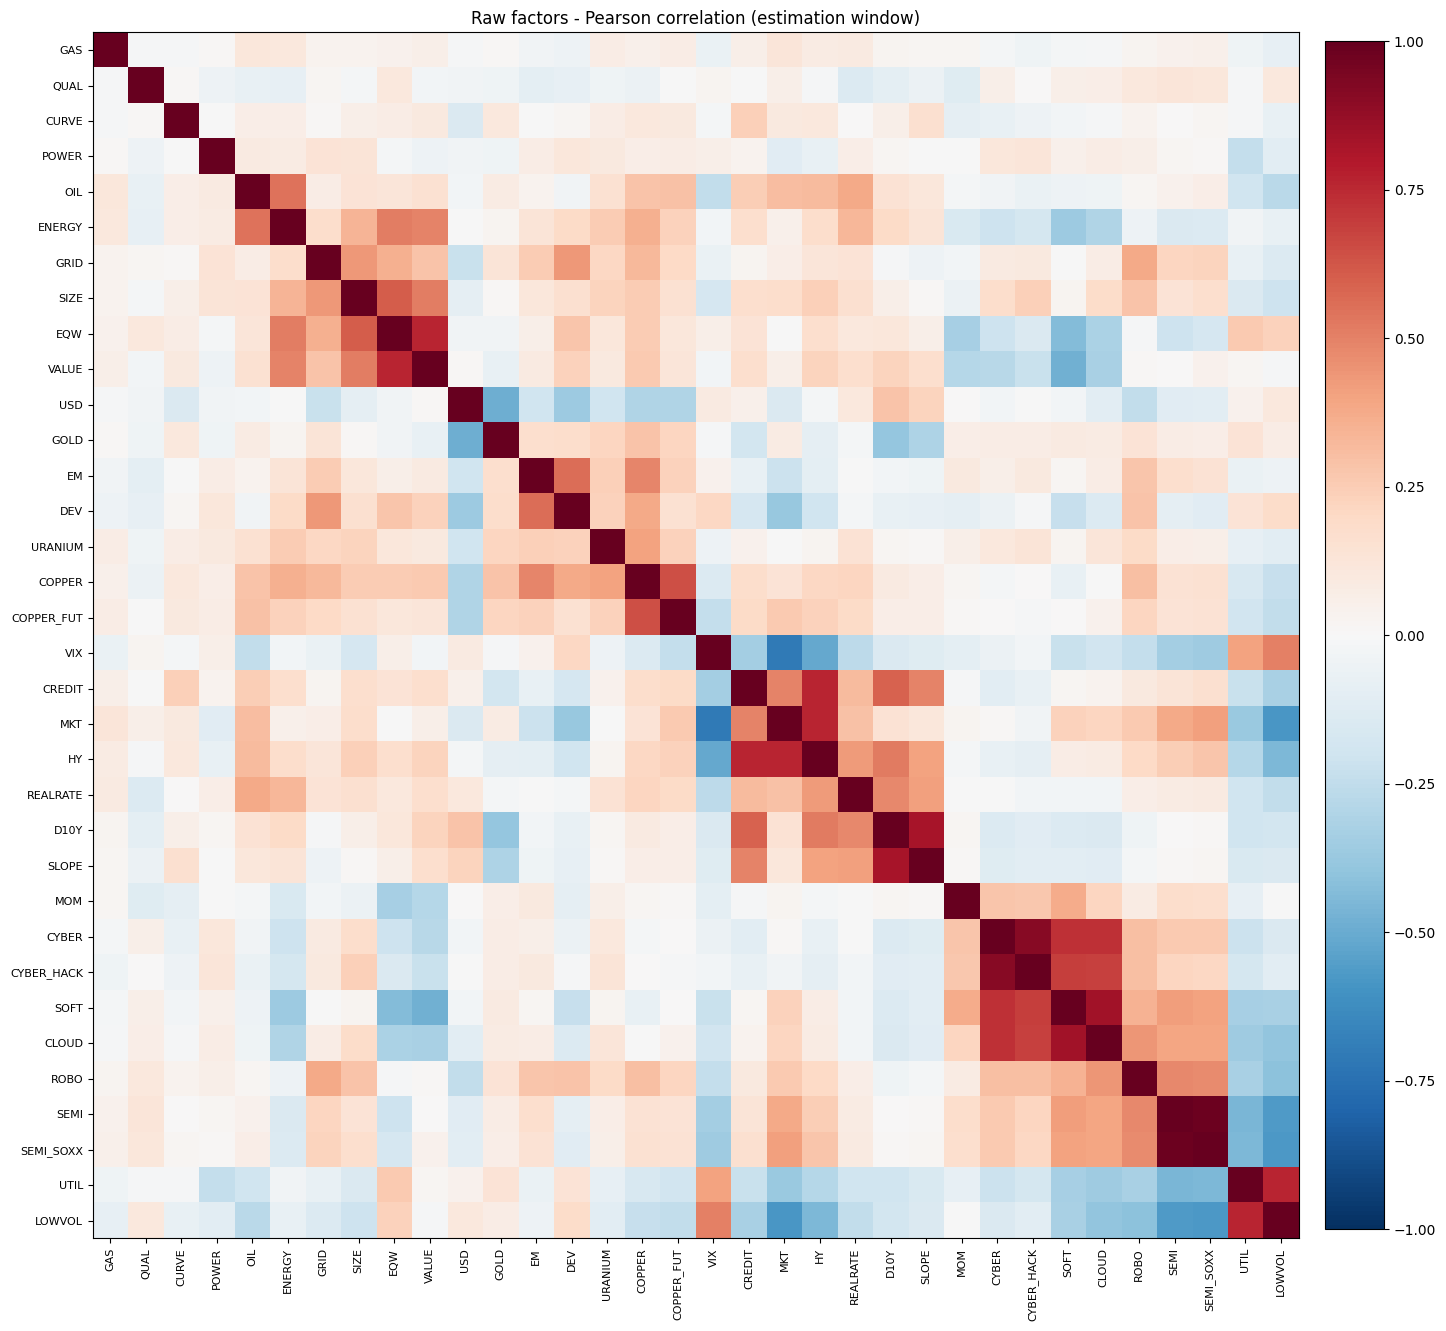

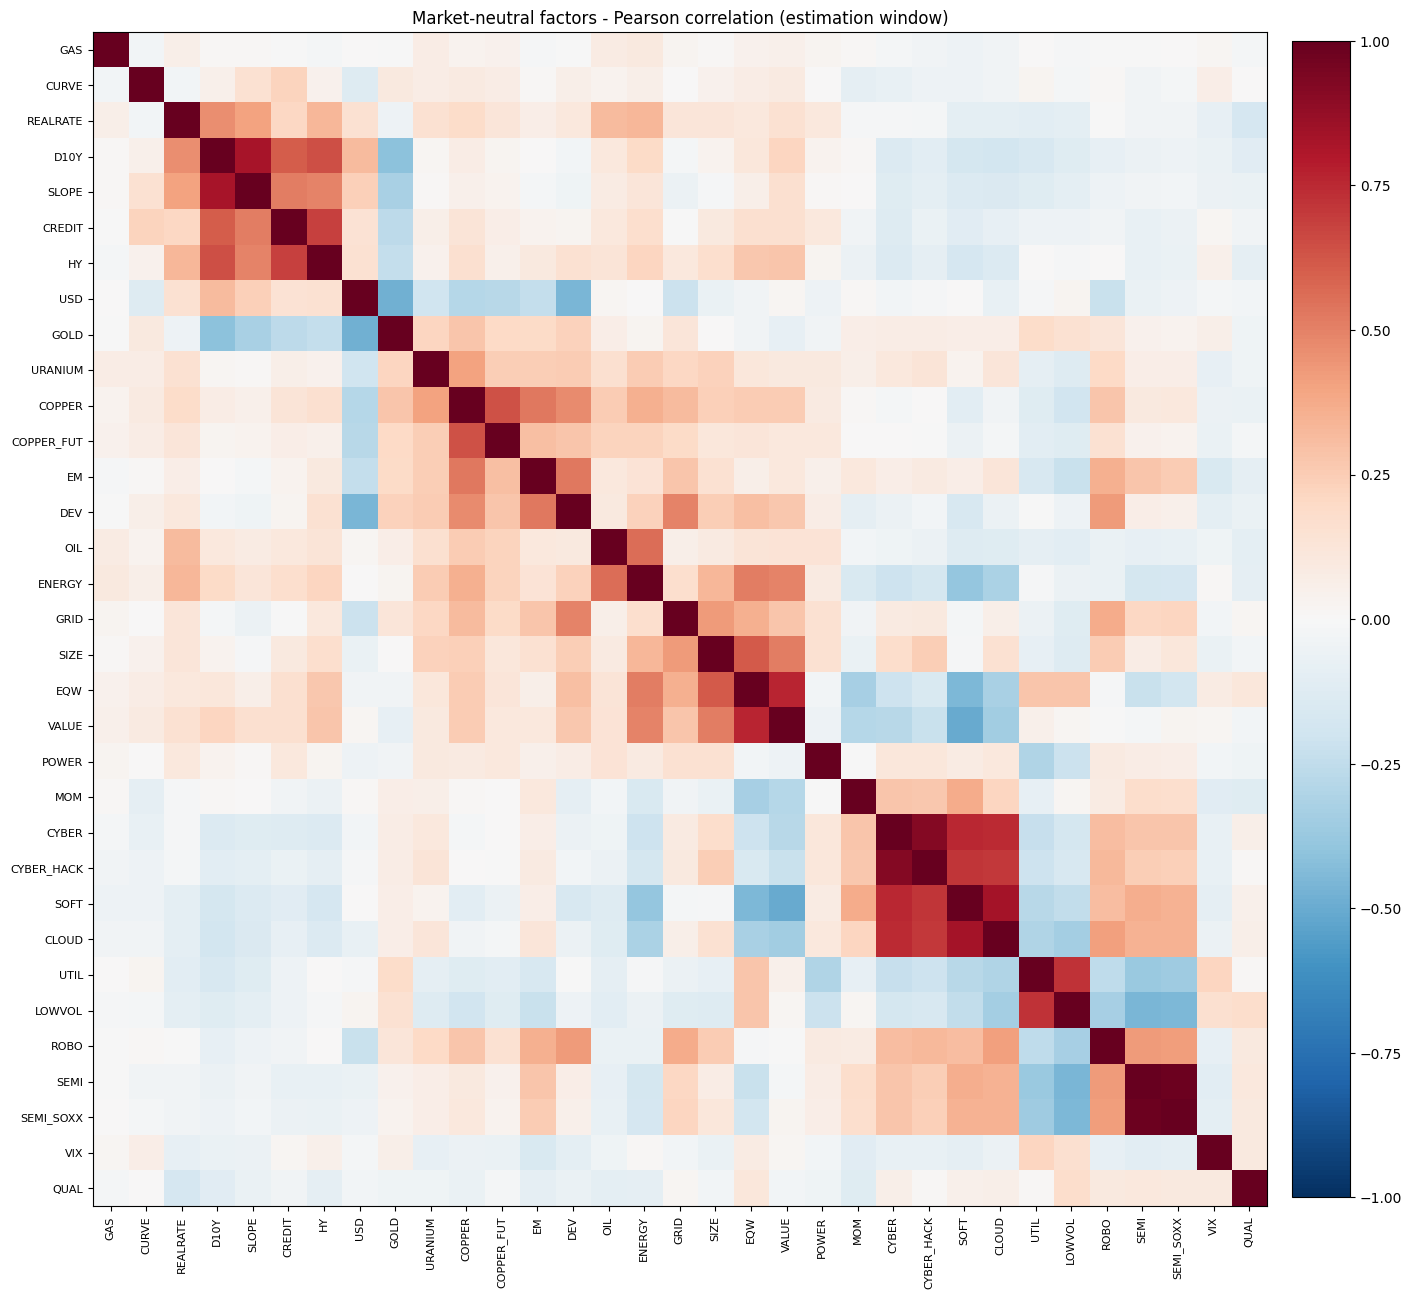

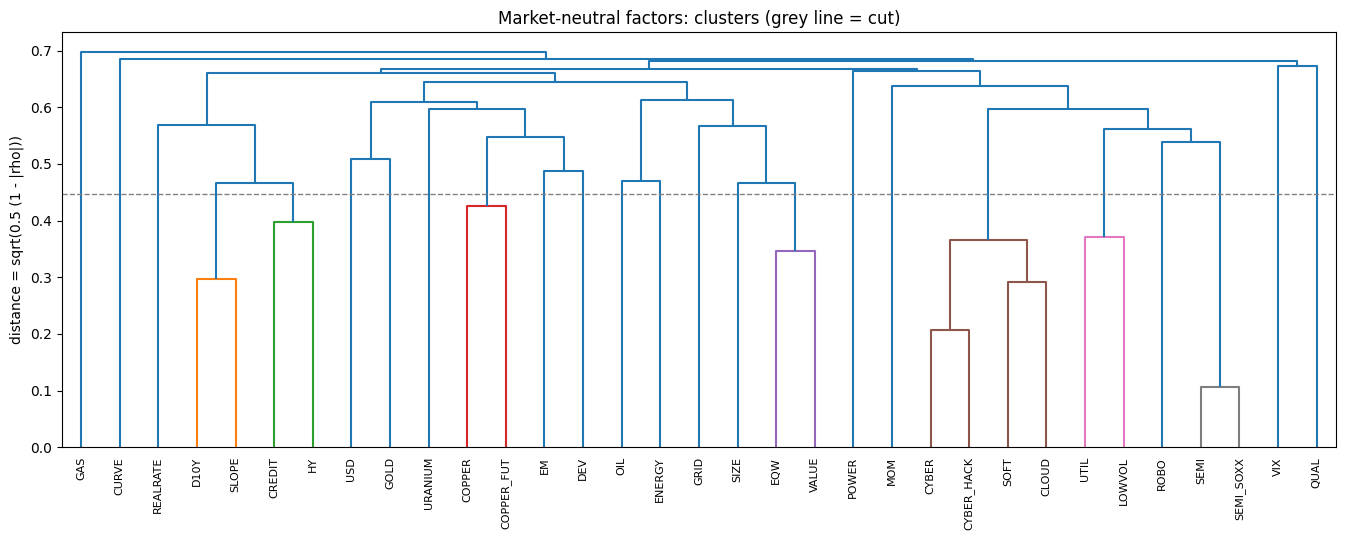

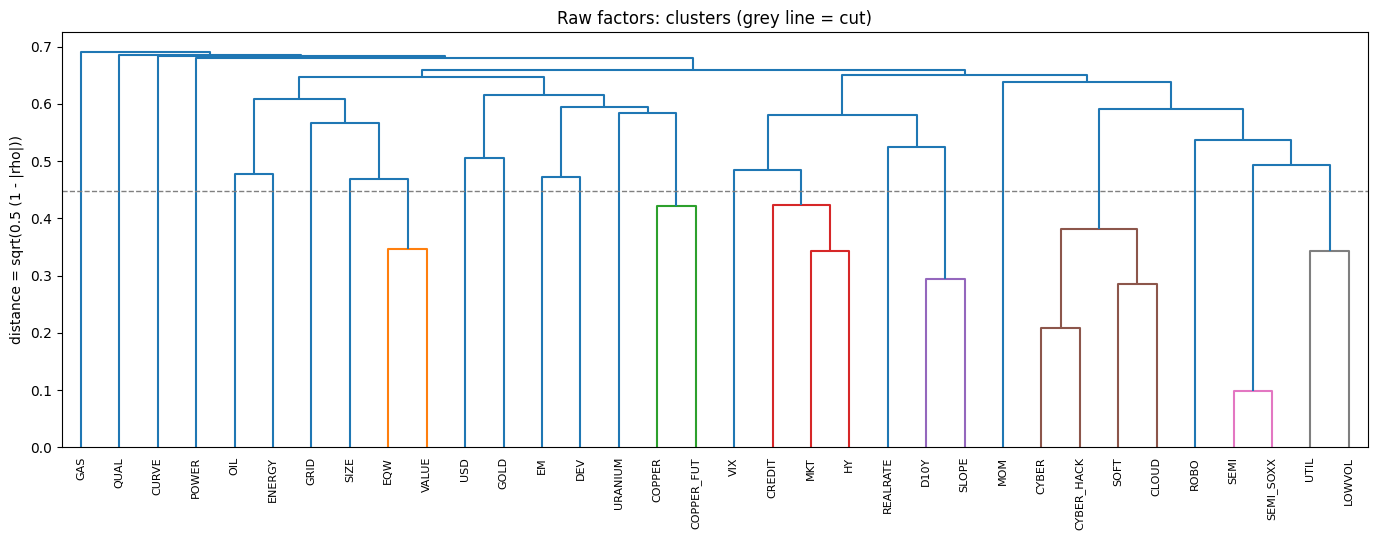

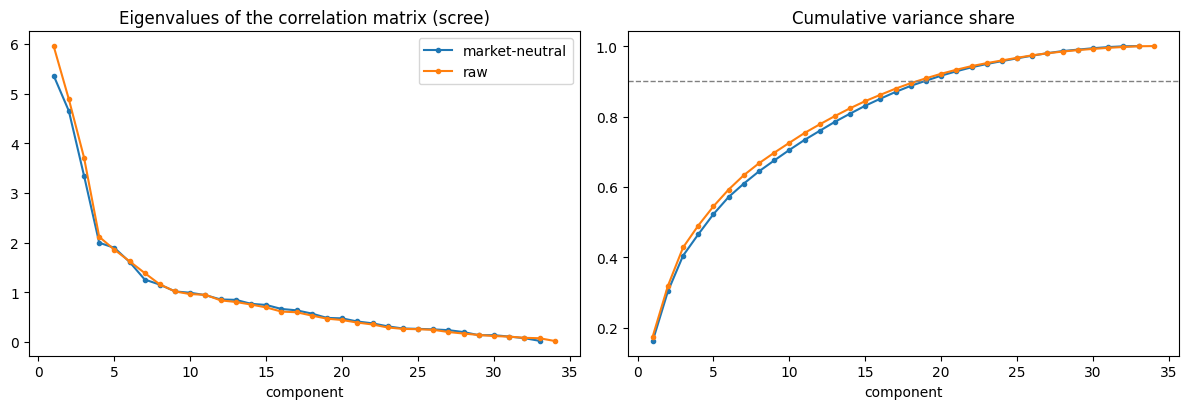

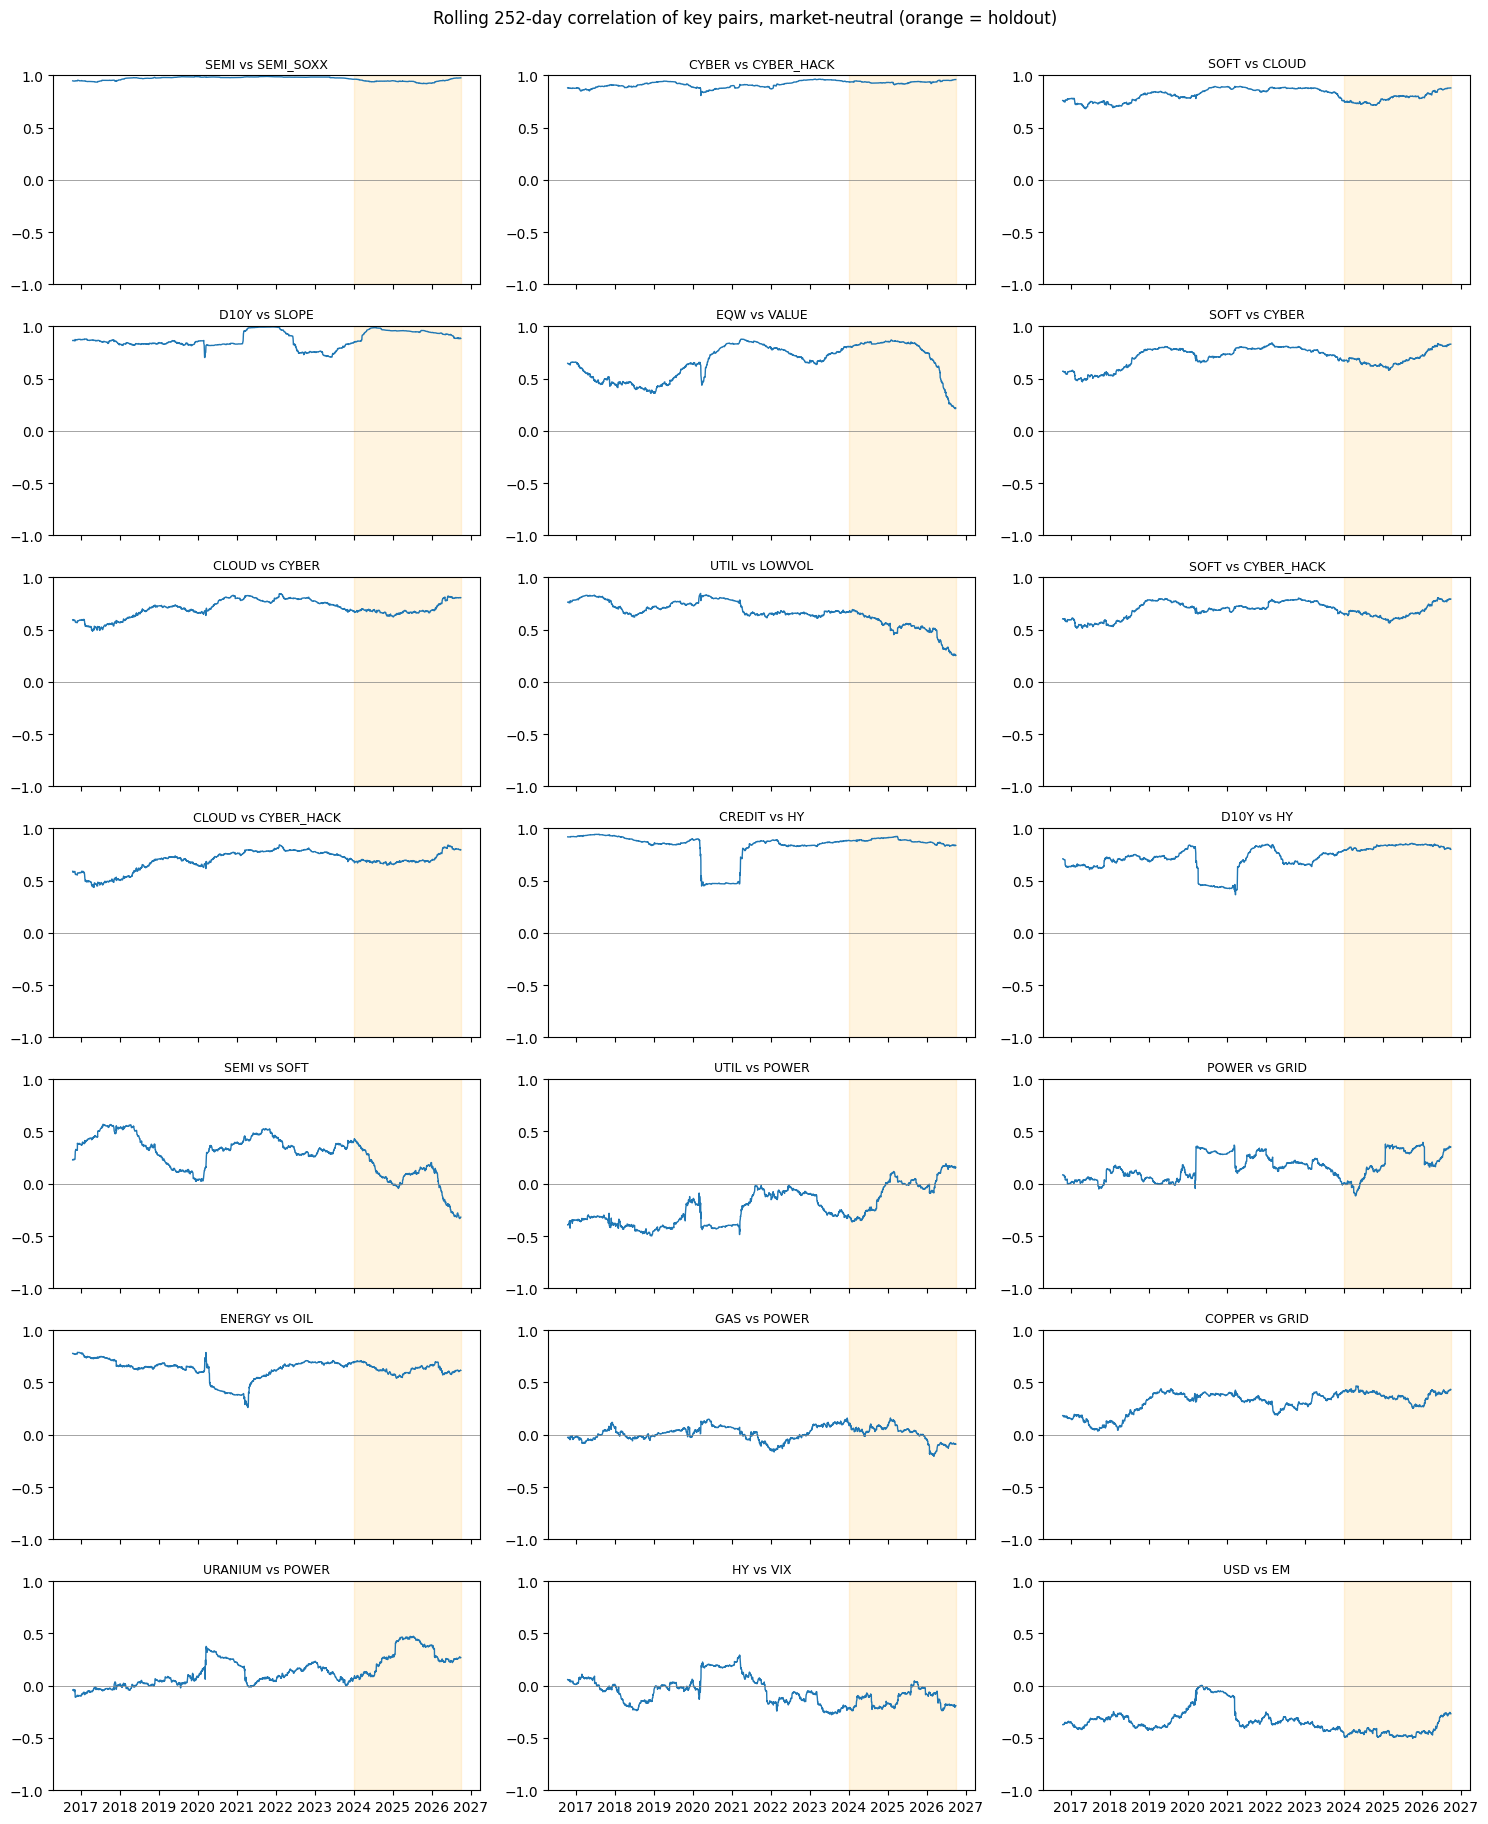

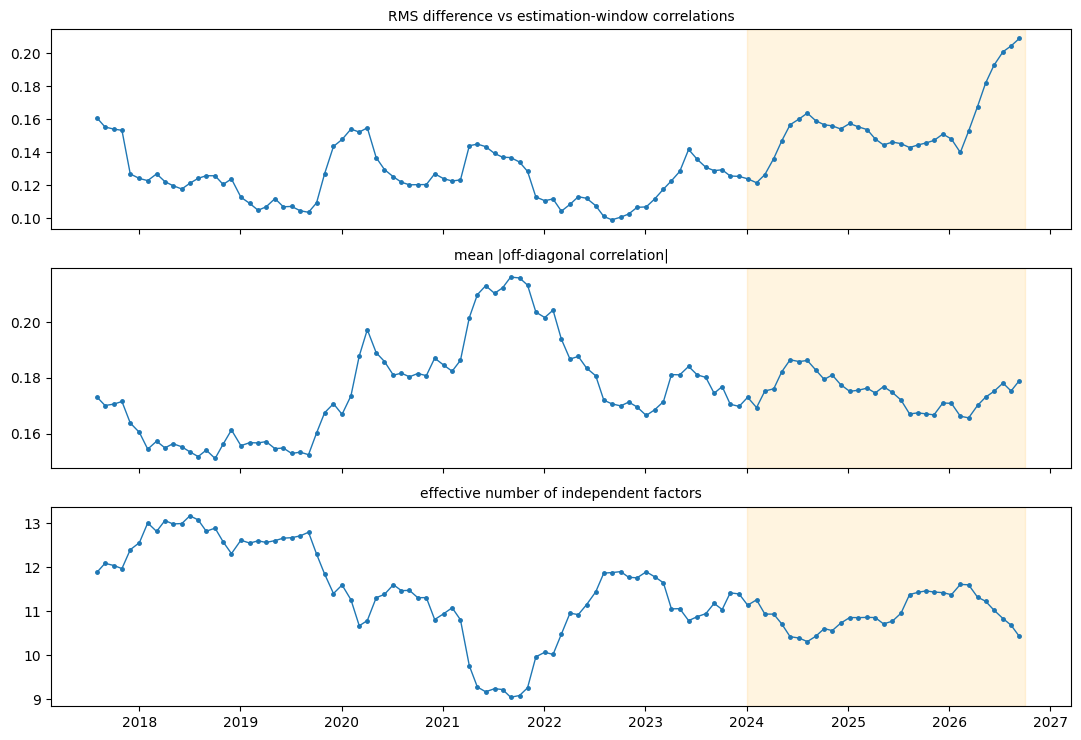

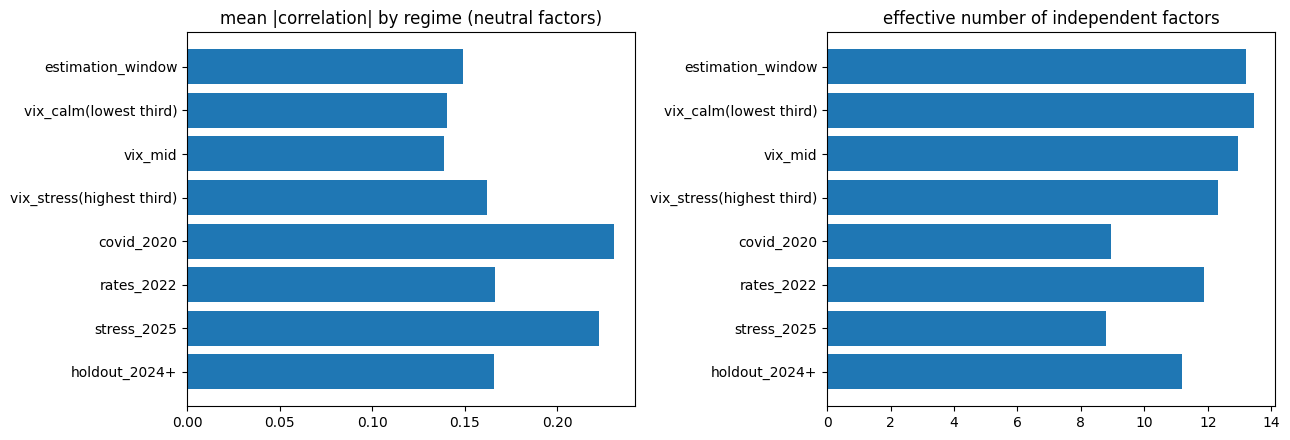

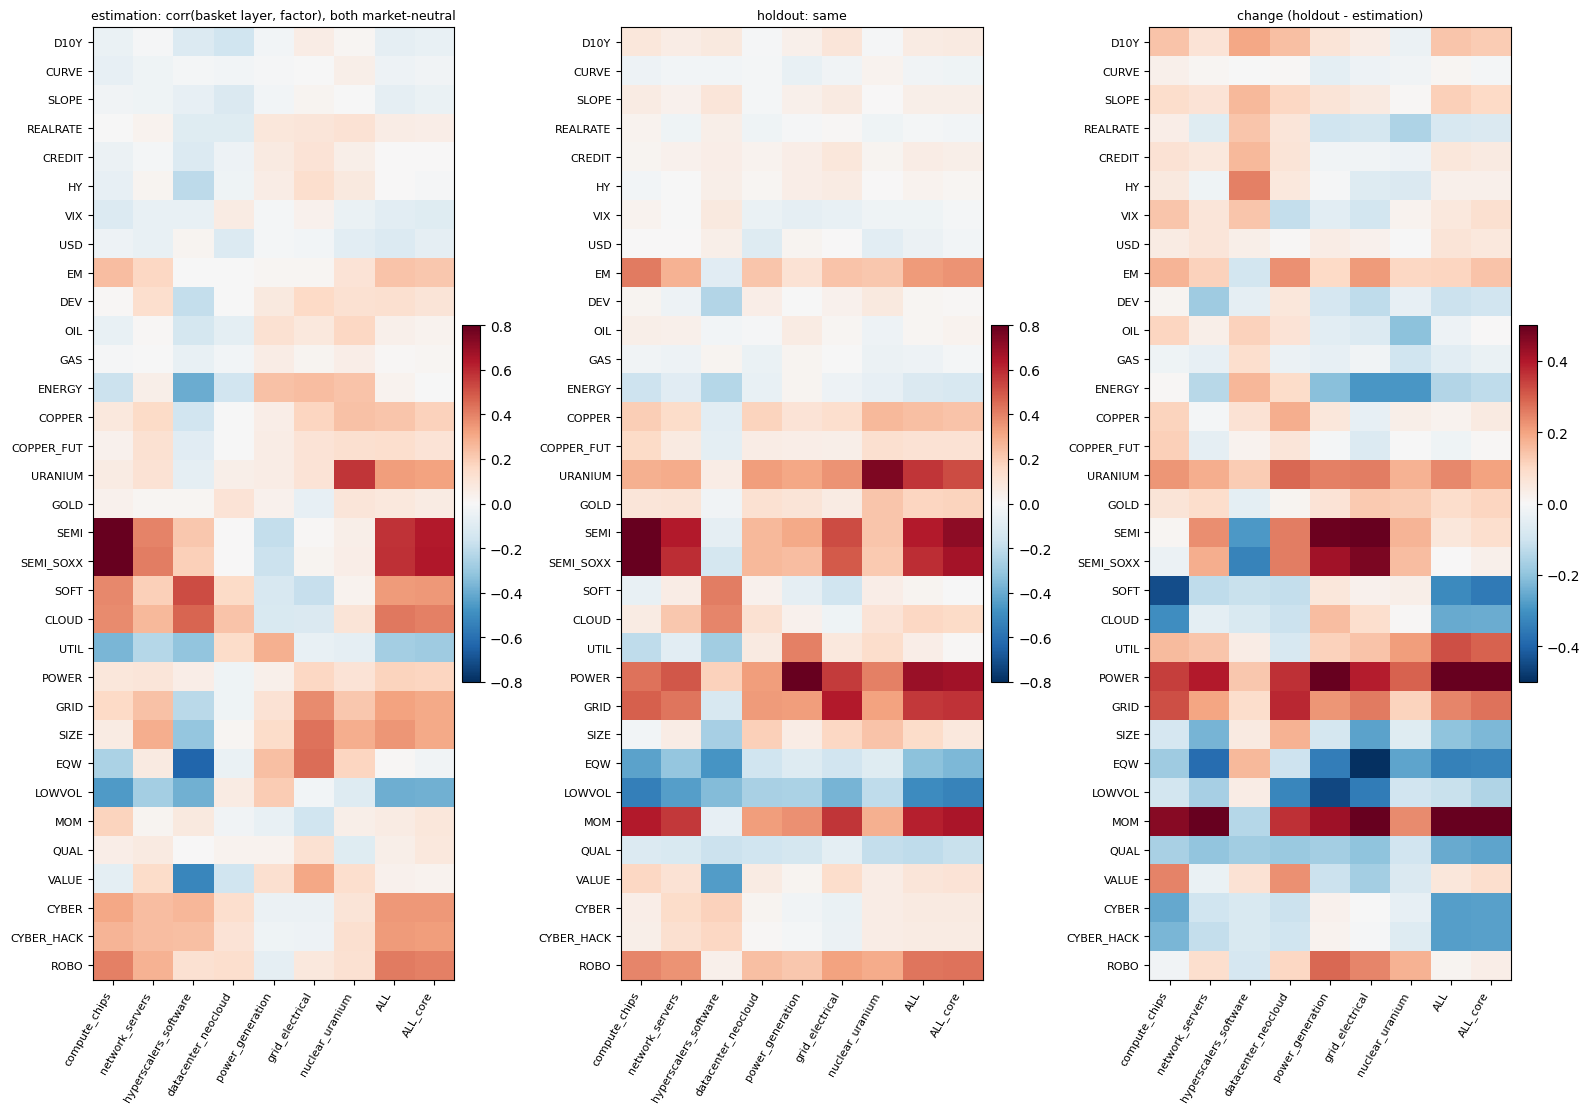

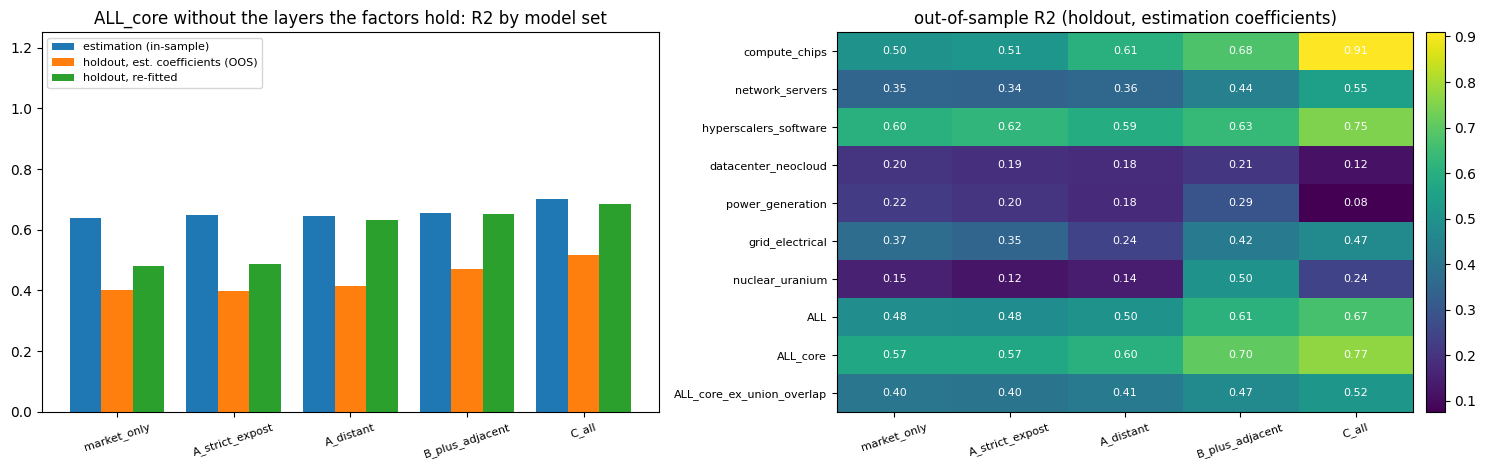

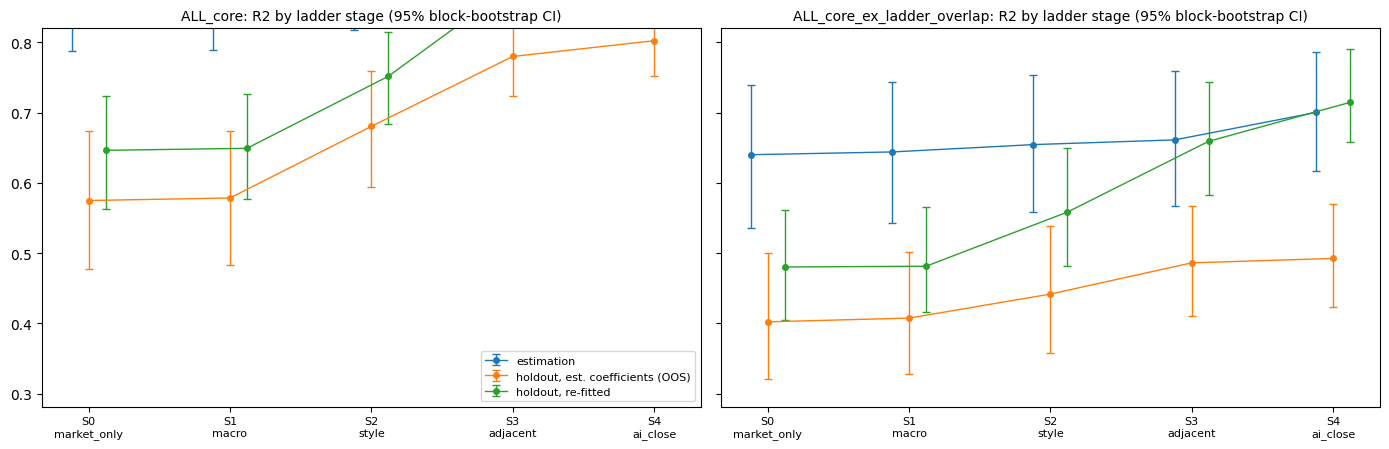

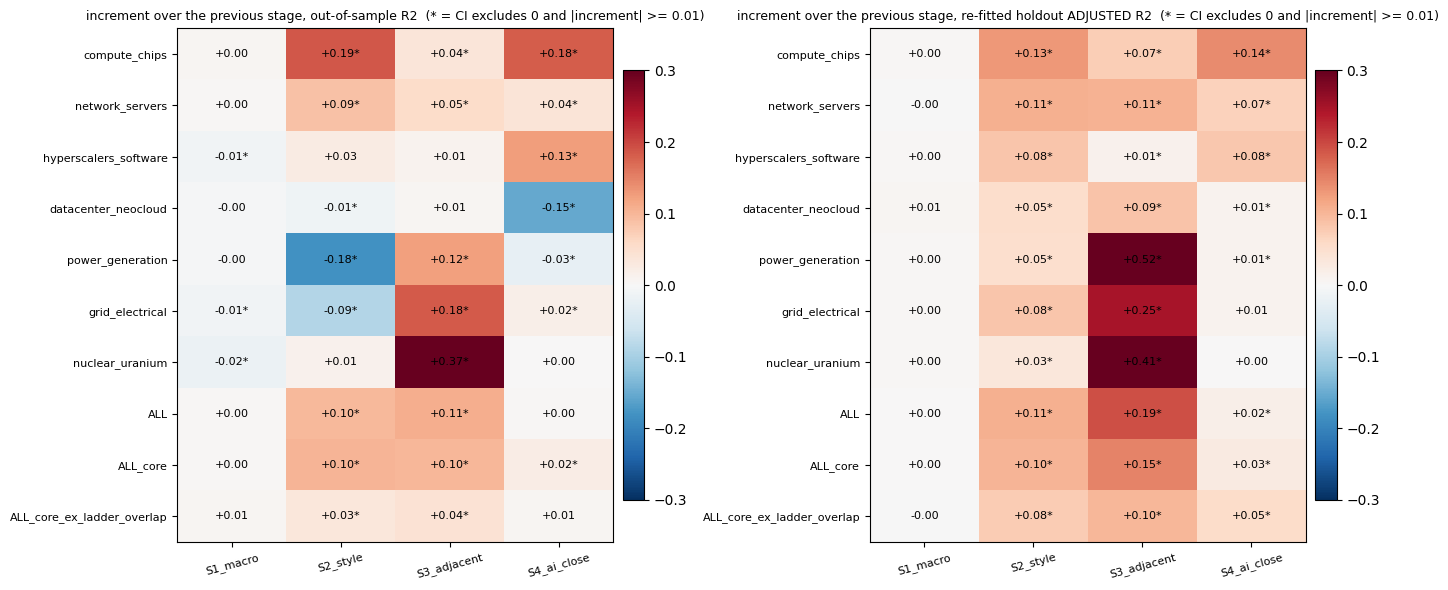

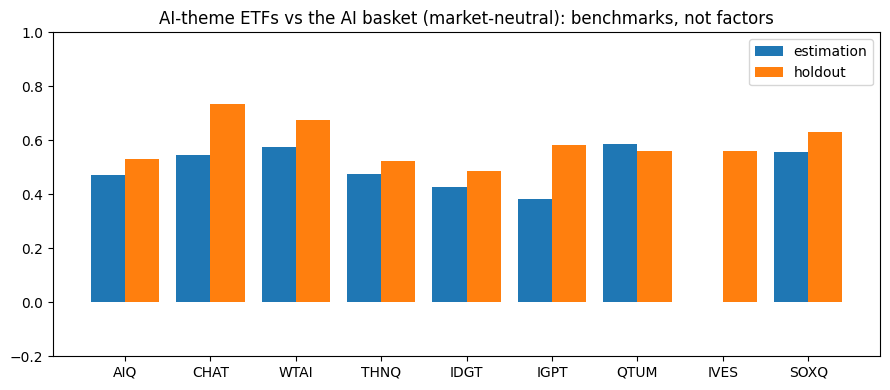

Estimation window 2017-01-03 -> 2023-12-29 (1760 days) | holdout 2024-01-02 -> 2026-10-01 (690 days)
Candidates 38 | eligible 34 | complete rows used: raw 1748, neutral 1748

=== 1. EXCLUDED CANDIDATES (and why) ===
          name         bucket first_valid  est_coverage                                                                reason
URANIUM_MINERS Metals/nuclear  2019-12-05      0.581818 starts 2019-12-05 after window start 2017-01-03; coverage 58.2% < 98%
     SEMI_SOXQ Semiconductors  2021-06-14      0.364773 starts 2021-06-14 after window start 2017-01-03; coverage 36.5% < 98%
         INFRA Software/cloud  2018-05-17      0.803977 starts 2018-05-17 after window start 2017-01-03; coverage 80.4% < 98%
         CAPEX     Grid/capex  2017-03-09      0.974432 starts 2017-03-09 after window start 2017-01-03; coverage 97.4% < 98%

=== 2. DESCRIPTIVES (estimation window; beta_to_mkt and r2_mkt show how much each factor is the market) ===
    factor  mean_ann  vol_ann   skew  ex_kurt

In [ ]:
res = get_results()
make_figures(res)
print_report(res)

## 16. Visual summary: staged R-squared by basket layer

The chart below decomposes out-of-sample R-squared into the market-only fit and the incremental effect of each later factor block. Solid segments improve fit; hatched segments reduce it.


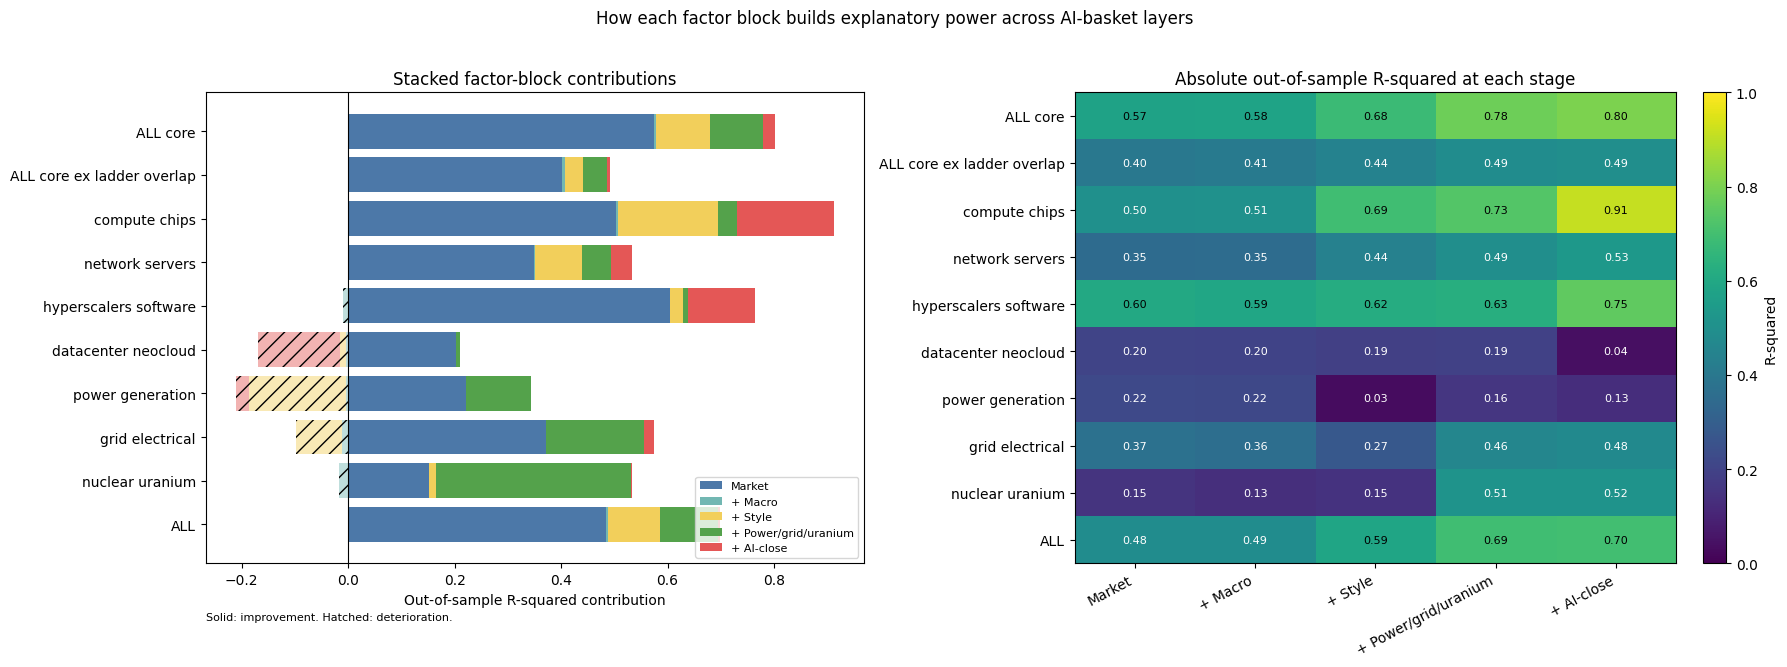

stage,Market,+ Macro,+ Style,+ Power/grid/uranium,+ AI-close
basket,,,,,
ALL_core,0.575,0.004,0.102,0.099,0.022
ALL_core_ex_ladder_overlap,0.402,0.005,0.034,0.044,0.006
compute_chips,0.503,0.005,0.187,0.036,0.182
network_servers,0.348,0.003,0.088,0.055,0.039
hyperscalers_software,0.604,-0.011,0.025,0.010,0.126
datacenter_neocloud,0.203,-0.003,-0.012,0.007,-0.154
power_generation,0.221,-0.004,-0.182,0.123,-0.025
grid_electrical,0.372,-0.011,-0.087,0.184,0.017
nuclear_uranium,0.152,-0.017,0.012,0.368,0.001


In [ ]:
# Run after: res = get_results()
STAGE_LABELS = {'S0_market_only': 'Market', 'S1_macro': '+ Macro', 'S2_style': '+ Style', 'S3_adjacent': '+ Power/grid/uranium', 'S4_ai_close': '+ AI-close'}
STAGE_COLORS = {'S0_market_only': '#4C78A8', 'S1_macro': '#72B7B2', 'S2_style': '#F2CF5B', 'S3_adjacent': '#54A24B', 'S4_ai_close': '#E45756'}

def plot_ladder_r2_stack(results, metric='r2_oos'):
    ladder = results['ladder_r2'].copy()
    stages = list(ladder['stage'].drop_duplicates())
    preferred = ['ALL_core', 'ALL_core_ex_ladder_overlap', 'compute_chips', 'network_servers', 'hyperscalers_software', 'datacenter_neocloud', 'power_generation', 'grid_electrical', 'nuclear_uranium']
    available = list(ladder['basket'].drop_duplicates())
    baskets = [b for b in preferred if b in available] + [b for b in available if b not in preferred]
    r2 = ladder.pivot(index='basket', columns='stage', values=metric).reindex(index=baskets, columns=stages)
    contribution = r2.diff(axis=1)
    contribution.iloc[:, 0] = r2.iloc[:, 0]

    fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(18, max(6, 0.55 * len(baskets) + 1)))
    y = np.arange(len(baskets)); positive = np.zeros(len(baskets)); negative = np.zeros(len(baskets))
    for stage in stages:
        values = contribution[stage].fillna(0).to_numpy()
        pos, neg = np.clip(values, 0, None), np.clip(values, None, 0)
        ax0.barh(y, pos, left=positive, color=STAGE_COLORS[stage], label=STAGE_LABELS[stage])
        ax0.barh(y, neg, left=negative, color=STAGE_COLORS[stage], alpha=0.45, hatch='//')
        positive += pos; negative += neg
    ax0.axvline(0, color='black', lw=0.8); ax0.set_yticks(y)
    ax0.set_yticklabels([b.replace('_', ' ') for b in baskets]); ax0.invert_yaxis()
    ax0.set_xlabel('Out-of-sample R-squared contribution'); ax0.set_title('Stacked factor-block contributions')
    ax0.legend(loc='lower right', fontsize=8); ax0.text(0, -0.12, 'Solid: improvement. Hatched: deterioration.', transform=ax0.transAxes, fontsize=8)

    im = ax1.imshow(r2.to_numpy(dtype=float), cmap='viridis', vmin=0, vmax=1, aspect='auto')
    ax1.set_xticks(range(len(stages))); ax1.set_xticklabels([STAGE_LABELS[s] for s in stages], rotation=28, ha='right')
    ax1.set_yticks(y); ax1.set_yticklabels([b.replace('_', ' ') for b in baskets])
    ax1.set_title('Absolute out-of-sample R-squared at each stage')
    for i in range(r2.shape[0]):
        for j in range(r2.shape[1]):
            v = r2.iat[i, j]
            if pd.notna(v): ax1.text(j, i, f'{v:.2f}', ha='center', va='center', color='white' if v < 0.55 else 'black', fontsize=8)
    fig.colorbar(im, ax=ax1, fraction=0.046, pad=0.04, label='R-squared')
    fig.suptitle('How each factor block builds explanatory power across AI-basket layers', y=1.02)
    fig.tight_layout(); plt.show()
    return r2, contribution

r2_oos_by_stage, r2_oos_increment = plot_ladder_r2_stack(res)
display(r2_oos_increment.round(3).rename(columns=STAGE_LABELS))
